## Import Data 

Load data from CSV and print out basic information

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('student_grade_ses_dataset.csv')

# Provide idea of the dataframe we are dealing with 
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

## Data Preprocessing: First steps

First initial steps in data preprocessing: removing duplicates and setting index columns. 

In [2]:
# 1. Cleaning Duplicate Rows 
duplicates = df[df.duplicated()]
print("Duplicate Rows:")
print(duplicates)

row_count_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
row_count_after = len(df)
print(f"{row_count_before} rows -> {row_count_after} after removing duplicates")

# 2. Set 'student_id' as the index and drop it from the standard columns
is_all_unique = df['student_id'].is_unique
print(f"Column student_id uniqueness: {is_all_unique}")
df = df.set_index('student_id', drop=True)

Duplicate Rows:
      student_id academic_year survey_date  age  gender  grade_level  \
2052   STU100247     2024-2025     10/3/25   13    Male            8   
2323   STU111139     2023-2024      5/3/25   17  Female           12   
4406   STU107482     2022-2023      1/5/25   14   Other            9   
5645   STU110619     2023-2024      8/5/25   11    Male            7   
5715   STU104160     2022-2023     12/5/25   13  Female            8   
5801   STU108370     2022-2023     22/3/25   18    Male           12   
6089   STU100191     2022-2023      8/3/25   15  Female           10   
6099   STU108270     2021-2022     16/4/25   12    Male            8   
7395   STU111279     2024-2025     19/4/25   15  Female            9   
7700   STU101857     2021-2022     10/5/25   14  Female           10   
7788   STU108388     2021-2022     10/4/25   18  Female           12   
7902   STU104036     2022-2023      3/4/25   14  Female           10   
7990   STU105705     2023-2024      7/3/25   15 

## Data Preprocessing: Missing data analysis 

Initial analysis on missing data and NaN cells to understand their missing pattern (random / pattern). 

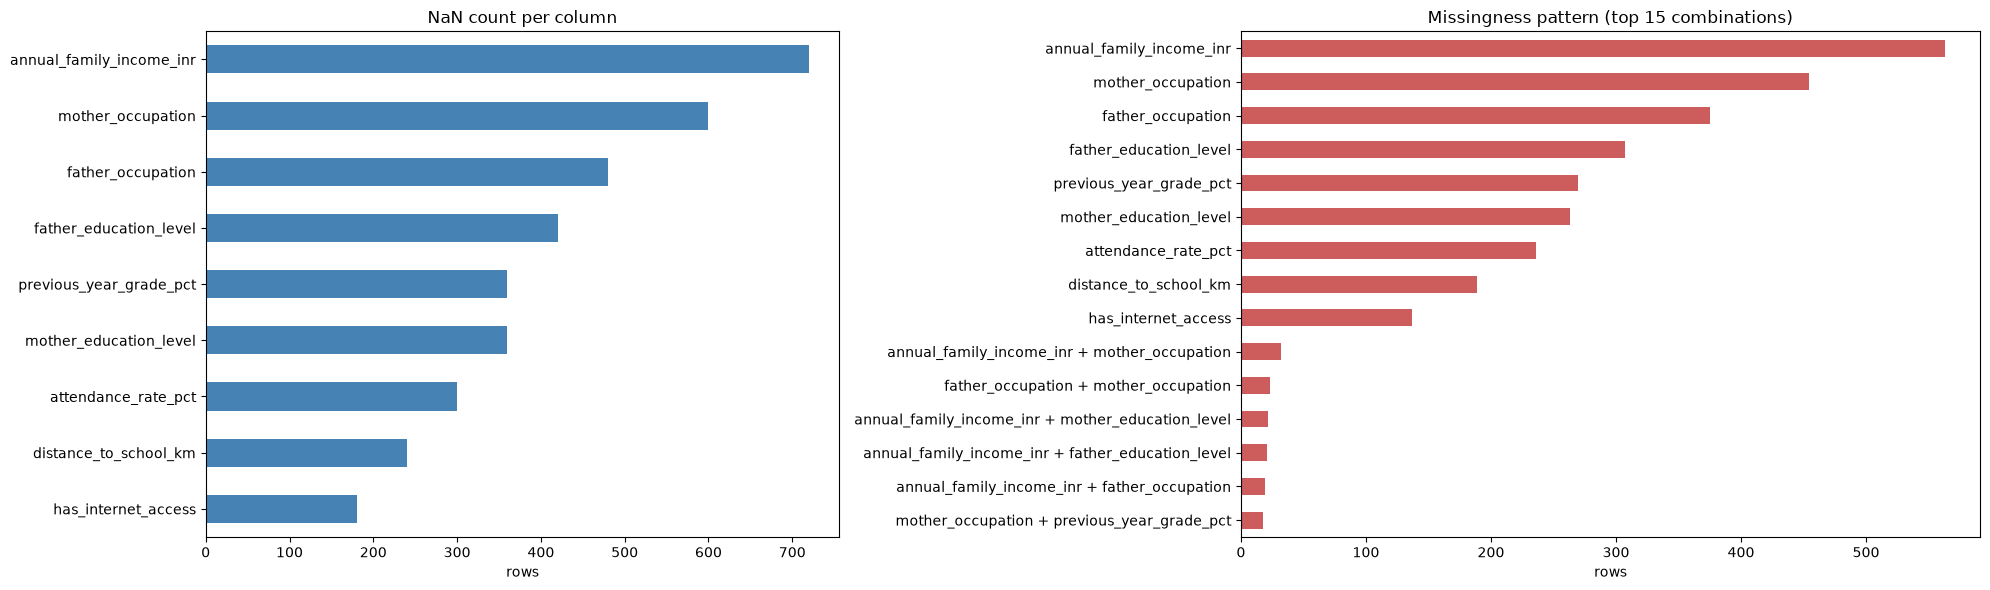

annual_family_income_inr                             563
mother_occupation                                    454
father_occupation                                    375
father_education_level                               307
previous_year_grade_pct                              270
mother_education_level                               263
attendance_rate_pct                                  236
distance_to_school_km                                189
has_internet_access                                  137
annual_family_income_inr + mother_occupation          32
father_occupation + mother_occupation                 23
annual_family_income_inr + mother_education_level     22
annual_family_income_inr + father_education_level     21
annual_family_income_inr + father_occupation          19
mother_occupation + previous_year_grade_pct           18
Name: count, dtype: int64


In [3]:
import matplotlib.pyplot as plt

na = df.isna()
cols = na.columns[na.any()]
na = na[cols]

fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={'width_ratios': [1.2, 1.4]})

# 1. NaN count per column
na.sum().sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('NaN count per column')
axes[0].set_xlabel('rows')

# 2. Missingness pattern: which combinations of columns are missing together
pattern = na[na.any(axis=1)].apply(lambda r: ' + '.join(r.index[r]), axis=1).value_counts()
pattern.head(15).sort_values().plot.barh(ax=axes[1], color='indianred')
axes[1].set_title('Missingness pattern (top 15 combinations)')
axes[1].set_xlabel('rows')

plt.tight_layout()
plt.show()

print(pattern.head(15))

## Data Preprocessing: Imputing Missing values
Parent education / occupation NULLs look random, so they become their own "Unknown" category. This learns nothing from the data, so its safe to do before CV.

In [ ]:
parent_cols = ['father_occupation', 'mother_occupation']
df[parent_cols] = df[parent_cols].fillna("Unknown")
nulls = df.isna().sum()
nulls[nulls > 0]

annual_family_income_inr    720
father_education_level      420
mother_education_level      360
has_internet_access         180
distance_to_school_km       240
attendance_rate_pct         300
previous_year_grade_pct     360
dtype: int64

## Data Preprocessing: Filling the rest

Fills values have to come from training rows only.
The `GroupImputer` does a fit and transform inside each CV fold.

| Column | Fill with | Why |
|---|---|---|
| `annual_family_income_inr` | median per `family_income_bracket`| bracket is complete and tracks income closely (Low (103k) vs High (3M)); the overall median (~350k) would put a high-income family in the middle |
| `distance_to_school_km` | median per `residence_type` | Rural (5.4 km) vs Urban (1.7 km) |
| `has_internet_access` | most common value per `residence_type`| Rural (36%) vs Urban (60%); the overall mode would give everyone 0 |
| `attendance_rate_pct`, `previous_year_grade_pct` | overall median | nothing else predicts them well (correlation <= 0.29); |

Rows with these missing values have about the same final grade as complete rows, so the gaps look random and simple filling is reasonable. `family_income_bracket` is dropped once income is filled.

In [5]:
from sklearn.base import BaseEstimator, TransformerMixin

class GroupImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        # income -> median of income bracket
        self.income_medians_ = X.groupby("family_income_bracket")["annual_family_income_inr"].median()

        # distance -> median of residence type
        self.distance_medians_ = X.groupby("residence_type")["distance_to_school_km"].median()

        # internet -> most common value for residence type
        internet = X.groupby("residence_type")["has_internet_access"]
        self.internet_modes_ = internet.agg(lambda s : s.mode()[0])

        # parent education level -> most common level of the income bracket
        father_edu = X.groupby("family_income_bracket")['father_education_level']
        mother_edu = X.groupby("family_income_bracket")['mother_education_level']
        self.father_edu_modes_ = father_edu.agg(lambda s: s.mode()[0])
        self.mother_edu_modes_ = mother_edu.agg(lambda s: s.mode()[0])

        # attendance and previous grade -> overall median
        self.other_medians_ = X[['attendance_rate_pct', 'previous_year_grade_pct']].median()

        self.columns_ = list(X.columns)

        return self

    def transform(self, X):
        X = X.copy()

        income_fill = X["family_income_bracket"].map(self.income_medians_)
        X["annual_family_income_inr"] = X["annual_family_income_inr"].fillna(income_fill)

        distance_fill = X["residence_type"].map(self.distance_medians_)
        X["distance_to_school_km"] = X["distance_to_school_km"].fillna(distance_fill)

        internet_fills = X["residence_type"].map(self.internet_modes_)
        X["has_internet_access"] = X["has_internet_access"].fillna(internet_fills)

        father_fill = X['family_income_bracket'].map(self.father_edu_modes_)
        X['father_education_level'] = X['father_education_level'].fillna(father_fill)

        mother_fill = X['family_income_bracket'].map(self.mother_edu_modes_)
        X['mother_education_level'] = X['mother_education_level'].fillna(mother_fill)

        X = X.fillna(self.other_medians_)

        return X

    def get_feature_names_out(self, input_features=None):
        return self.columns_

## Data Preprocessing: Visualisation of predictors and targets datatypes

Describe the data visually to get a lay of the land and the data types that we are working with. 

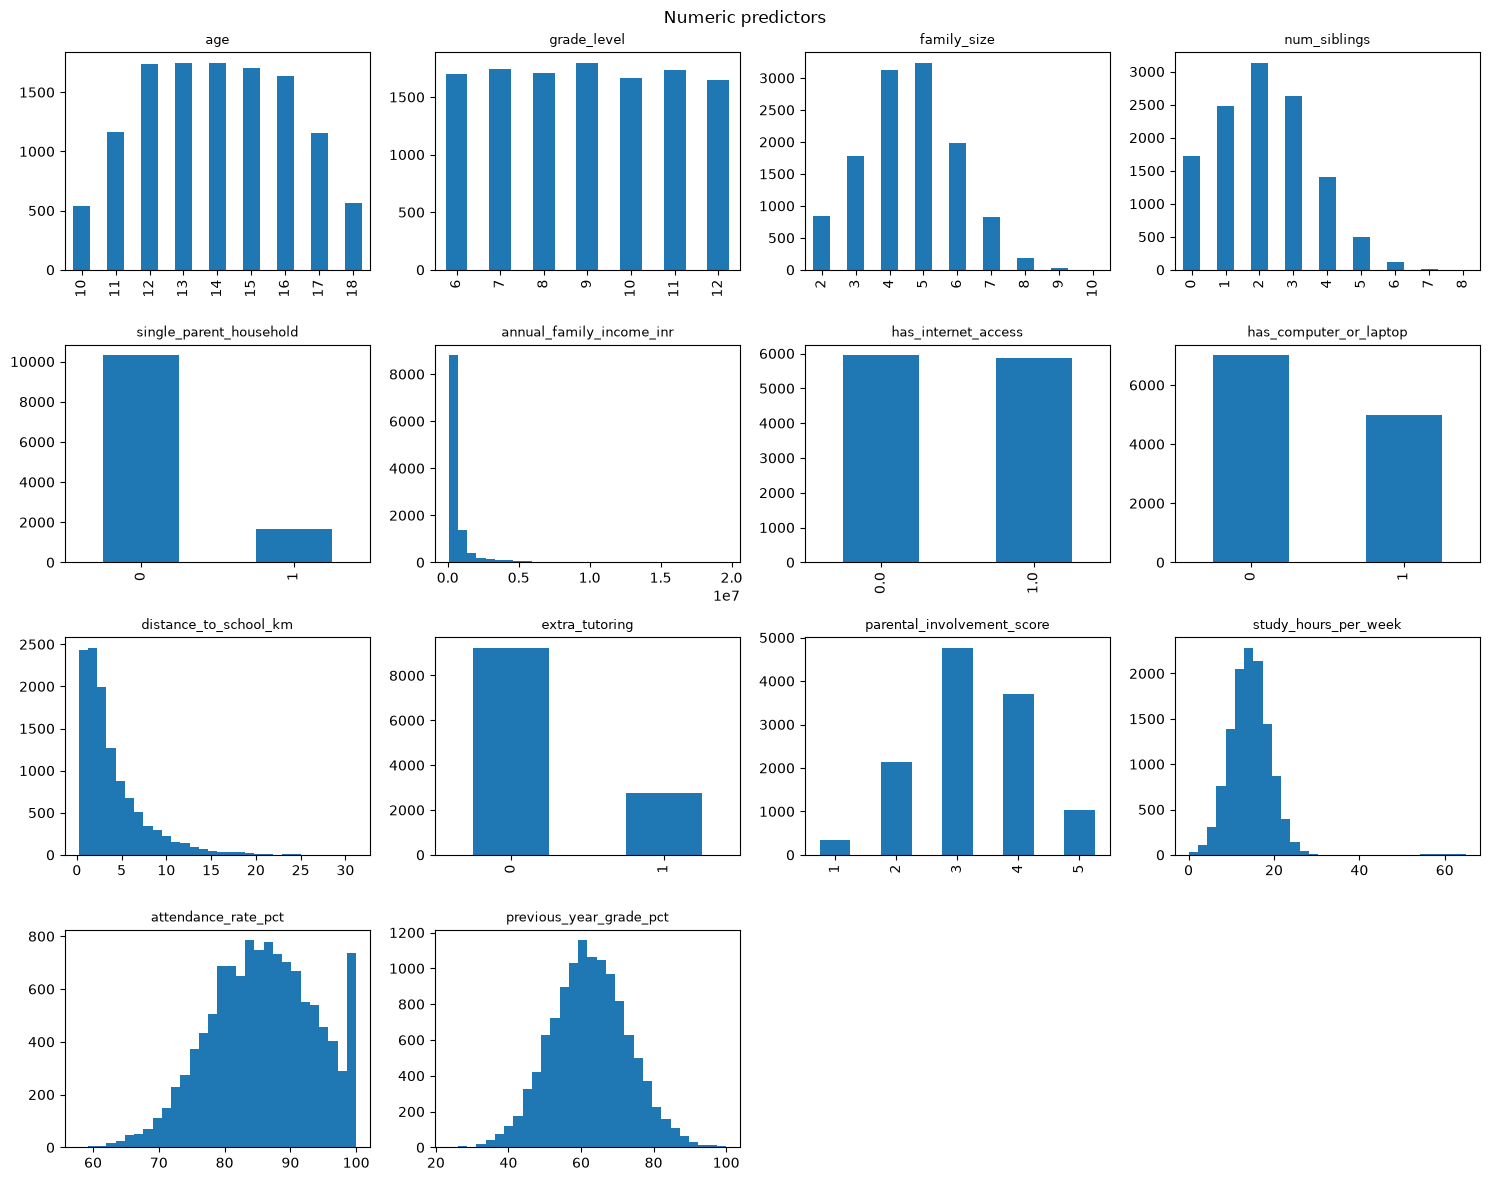

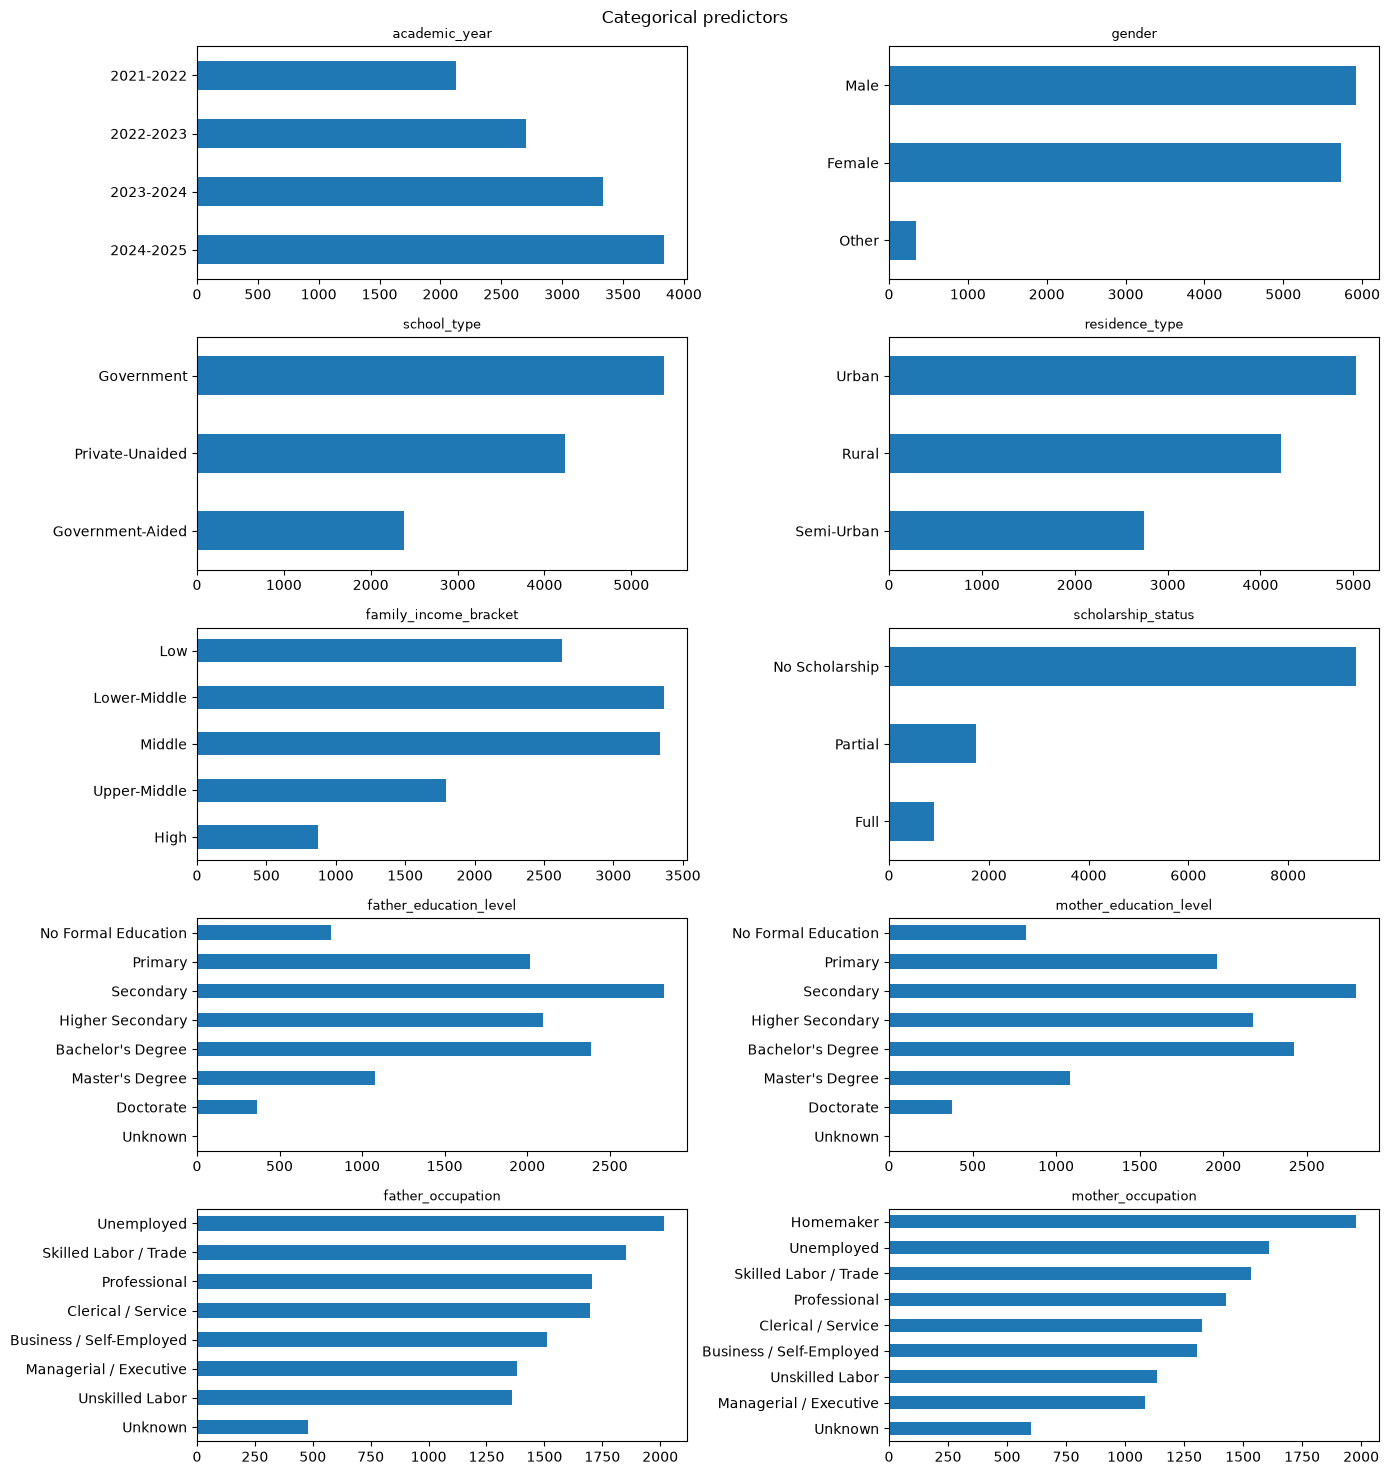

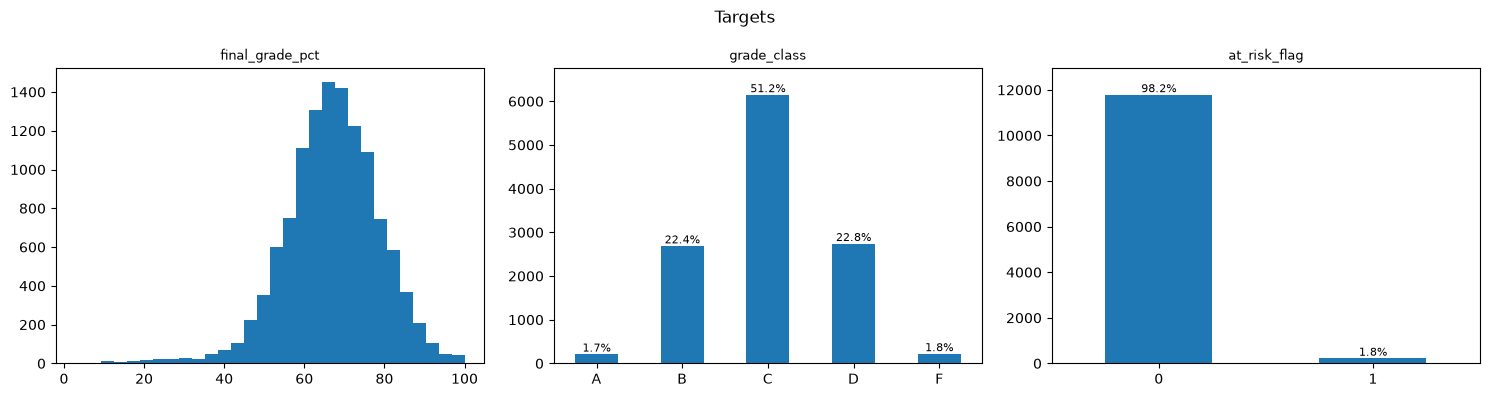

In [6]:
# Visualisation of predictors and targets

TARGET_COLS = ['final_grade_pct', 'grade_class', 'at_risk_flag']

# ===========================================================================================================

# Figure 1: numeric predictors
numeric_predictors = df.select_dtypes('number').columns.drop(TARGET_COLS, errors='ignore')

fig, axes = plt.subplots(4, 4, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_predictors):
    ax = axes[i]
    if df[col].nunique() <= 10:
        df[col].value_counts().sort_index().plot(kind='bar', ax=ax)
        ax.set_xlabel('')
    else:
        df[col].hist(bins=30, ax=ax, grid=False)
    ax.set_title(col, fontsize=9)

for ax in axes[len(numeric_predictors):]:
    ax.set_visible(False)

fig.suptitle('Numeric predictors')
plt.tight_layout()
plt.show()

# ===========================================================================================================

# Figure 2: categorical predictors
# Columns with a natural order keep it; the others are sorted by count
EDUCATION_ORDER = [
    'No Formal Education',
    'Primary',
    'Secondary',
    'Higher Secondary',
    "Bachelor's Degree",
    "Master's Degree",
    'Doctorate',
    'Unknown',
]
CATEGORY_ORDERS = {
    'academic_year':            ['2021-2022', '2022-2023', '2023-2024', '2024-2025'],
    'family_income_bracket':    ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High'],
    'father_education_level':   EDUCATION_ORDER,
    'mother_education_level':   EDUCATION_ORDER,
    'scholarship_status':       ['No Scholarship', 'Partial', 'Full'],
}
categorical_predictors = [
    'academic_year',
    'gender',
    'school_type',
    'residence_type',
    'family_income_bracket',
    'scholarship_status',
    'father_education_level',
    'mother_education_level',
    'father_occupation',
    'mother_occupation',
]

fig, axes = plt.subplots(5, 2, figsize=(14, 15))

for ax, col in zip(axes.flatten(), categorical_predictors):
    counts = df[col].value_counts()
    if col in CATEGORY_ORDERS:
        counts = counts.reindex(CATEGORY_ORDERS[col])
    counts.plot(kind='barh', ax=ax)
    ax.invert_yaxis()      # first category at the top
    ax.set_ylabel('')
    ax.set_title(col, fontsize=9)

fig.suptitle('Categorical predictors')
plt.tight_layout()
plt.show()

# ===========================================================================================================

# Figure 3: targets
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df['final_grade_pct'].hist(bins=30, ax=axes[0], grid=False)
axes[0].set_title('final_grade_pct', fontsize=9)

grade_counts = df['grade_class'].value_counts().reindex(['A', 'B', 'C', 'D', 'F'])
at_risk_counts = df['at_risk_flag'].value_counts().sort_index()

# The rare classes are hard to read from bar height alone, so label the share of students
for ax, counts, title in [(axes[1], grade_counts, 'grade_class'), (axes[2], at_risk_counts, 'at_risk_flag')]:
    counts.plot(kind='bar', ax=ax, rot=0)
    ax.bar_label(ax.containers[0], labels=[f'{count / len(df):.1%}' for count in counts], fontsize=8)
    ax.margins(y=0.1)      # room for the labels above the tallest bar
    ax.set_xlabel('')
    ax.set_title(title, fontsize=9)

fig.suptitle('Targets')
plt.tight_layout()
plt.show()

## Data Preprocessing: Skewed income column

From figures, we can see `annual_family_income_inr` is very right-skewed, due to the presence of a few ultra-rich families that stretch the axis while majority sits nearer to the lower end. Models like linear regression, logistics regression, K-means clustering etc are sensitive to extreme values and perform better when features are normally distributed. Hence, a log transformation is ideal here as it preserves rank as it is a monotonically increasing function. We will log transform the income column later on during the data prep stage. 

In [73]:
print(f"annual_family_income_inr skew: {df['annual_family_income_inr'].skew()}")
print(f"log_income skew: {np.log(df['annual_family_income_inr']).skew()}")

from sklearn.preprocessing import FunctionTransformer

def log_transform():
    return FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )

annual_family_income_inr skew: 4.530329465806571
log_income skew: 0.4205426254784579


## Data Preprocessing: Schema Setup

Based off the variable histograms above, we can see clearly which of the columns are discrete/continuous/categorical and form the column schema below. Under categorical columns, we further observe which columns have a natural ordering (ordinal) and which doesn't (one-hot). 

In [ ]:
# Schema Setup 

REGRESSION_TARGET     = 'final_grade_pct'
CLASSIFICATION_TARGET = 'at_risk_flag'

# Continuous values 
CONTINUOUS_COLS = [
    'distance_to_school_km', 
    'study_hours_per_week', 
    'attendance_rate_pct',          
    'previous_year_grade_pct', 
    'annual_family_income_inr'
]

# Integer labels
DISCRETE_COLS = [
    'age', 
    'grade_level', 
    'family_size', 
    'num_siblings', 
    'single_parent_household',
    'has_internet_access', 
    'has_computer_or_laptop', 
    'extra_tutoring',
    'parental_involvement_score'
]

# Categorical columns - text labels
ONEHOT_COLUMNS = [
    'academic_year', 
    'gender', 
    'school_type', 
    'residence_type', 
    'father_occupation',
    'mother_occupation', 
]

ORDINAL_COLUMNS = [
    'family_income_bracket',
    'father_education_level', 
    'mother_education_level', 
    'scholarship_status'
] 

CATEGORICAL_COLS = ONEHOT_COLUMNS + ORDINAL_COLUMNS
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

# Setup X predictors
 
X = df[PREDICTOR_COLS]
print('X:', X.shape)

## Data Preprocessing: Predictor correlations with the regression target

Pearson correlations show the direction and strength of each numeric predictor's linear association with `final_grade_pct`. Text categorical predictors are excluded, as in the predictor correlation heatmap below. Correlations use available predictor-target pairs (without imputation) across the deduplicated data and are descriptive, not evidence of causation.


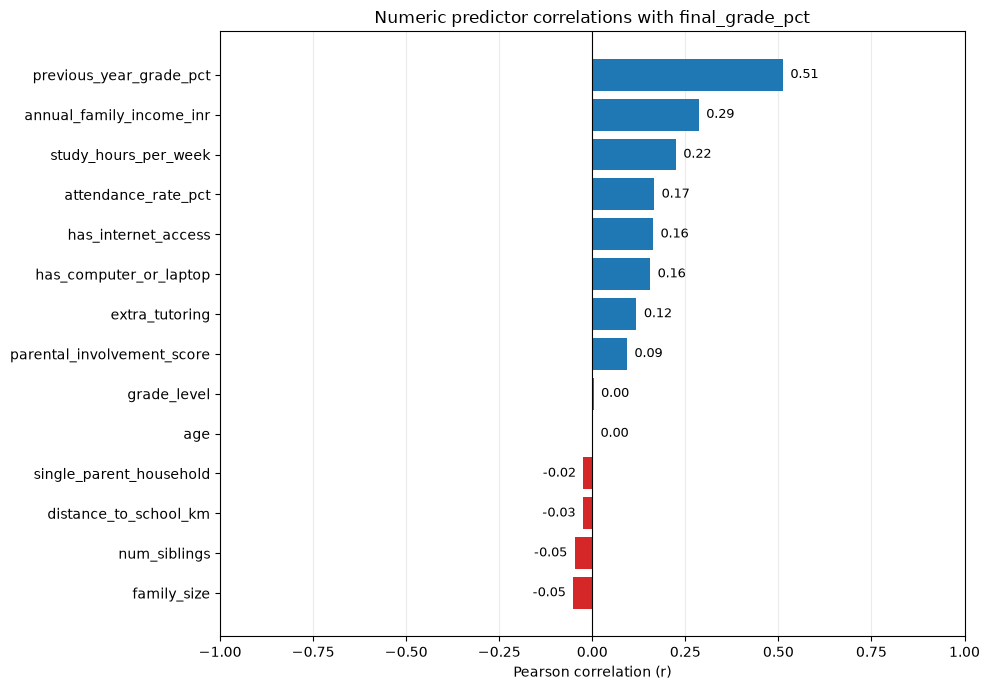

In [10]:
# Correlation of each numeric predictor with the regression target
# corrwith aligns rows and excludes missing predictor-target pairs.
target_correlations = X[NUMERIC_COLS].corrwith(df[REGRESSION_TARGET]).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['tab:blue' if value >= 0 else 'tab:red' for value in target_correlations]
ax.barh(target_correlations.index, target_correlations.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel('Pearson correlation (r)')
ax.set_title(f'Numeric predictor correlations with {REGRESSION_TARGET}')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)

for row, value in enumerate(target_correlations):
    if pd.notna(value):
        ax.text(value + (0.02 if value >= 0 else -0.02), row, f'{value:.2f}',
                va='center', ha='left' if value >= 0 else 'right', fontsize=9)

plt.tight_layout()
plt.show()


### Predictor relationships with the regression target

Continuous predictors use scatterplots, with each point representing a student. Discrete predictors (from `age` through `parental_involvement_score`, including binary flags) use box plots of `final_grade_pct` at each observed level. Boxes show the middle 50% of grades and the median; whiskers extend to the most extreme values within 1.5 times the interquartile range, and points beyond them are shown individually.

Each panel reports Pearson's r using available predictor-target pairs. Income uses a logarithmic horizontal axis to make its skewed distribution easier to see; its reported correlation still uses the original income values.

Scatterplots include a least-squares fit and a shaded band of ±1 residual standard deviation in grade percentage points, estimated as `sqrt(sum(residuals**2) / (n - 2))`. The band describes scatter around the fit, rather than a confidence interval for the mean. Fits use the original predictor values, so the income fit appears curved on its logarithmic axis.


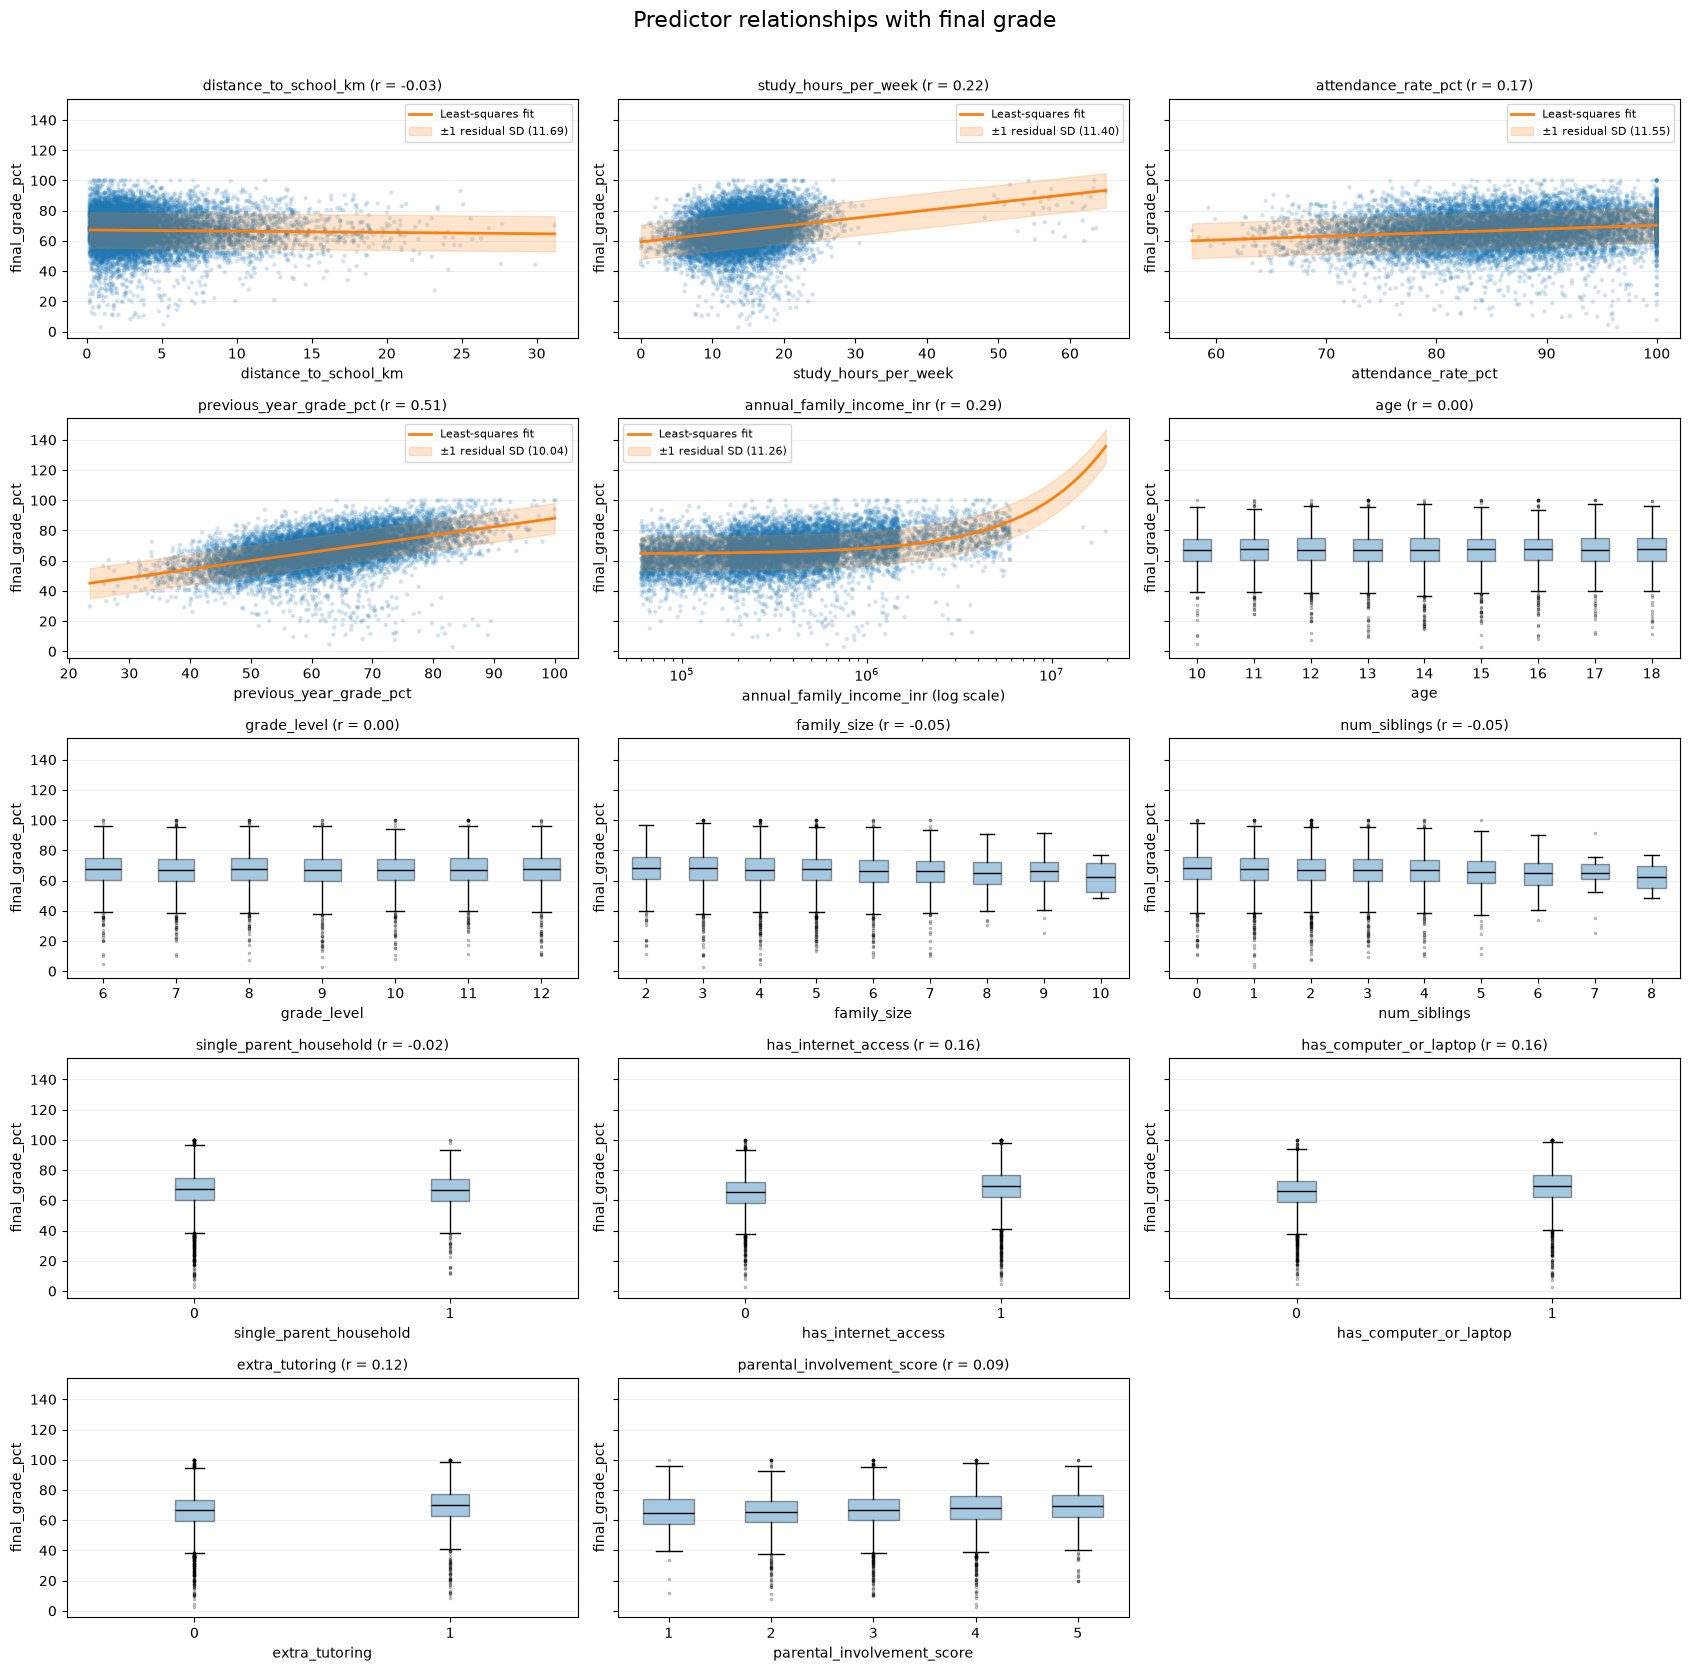

In [11]:
# Scatterplots for continuous predictors; box plots for discrete predictors.
ncols = 3
nrows = (len(NUMERIC_COLS) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(17, 3.4 * nrows),
                         sharey=True, squeeze=False)

for ax, predictor in zip(axes.flat, NUMERIC_COLS):
    pairs = pd.concat([X[predictor], df[REGRESSION_TARGET]], axis=1).dropna()
    if predictor in DISCRETE_COLS:
        levels = sorted(pairs[predictor].unique())
        grade_groups = [pairs.loc[pairs[predictor] == level, REGRESSION_TARGET]
                        for level in levels]
        positions = np.arange(1, len(levels) + 1)
        ax.boxplot(grade_groups, positions=positions, patch_artist=True,
                   boxprops={'facecolor': 'tab:blue', 'alpha': 0.4},
                   medianprops={'color': 'black'},
                   flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.3})
        ax.set_xticks(positions, [f'{level:g}' for level in levels])
    else:
        ax.scatter(pairs[predictor], pairs[REGRESSION_TARGET],
                   s=10, alpha=0.2, edgecolors='none', rasterized=True)
        x_values = pairs[predictor].to_numpy(dtype=float)
        y_values = pairs[REGRESSION_TARGET].to_numpy(dtype=float)
        if len(pairs) > 2 and pairs[predictor].nunique() > 1:
            slope, intercept = np.polyfit(x_values, y_values, deg=1)
            residuals = y_values - (slope * x_values + intercept)
            residual_sd = np.sqrt(np.sum(residuals ** 2) / (len(pairs) - 2))
            # Sample evenly on the displayed axis; fit uses original predictor units.
            if predictor == 'annual_family_income_inr':
                x_fit = np.geomspace(x_values.min(), x_values.max(), 200)
            else:
                x_fit = np.linspace(x_values.min(), x_values.max(), 200)
            y_fit = slope * x_fit + intercept
            ax.plot(x_fit, y_fit, color='tab:orange', linewidth=2,
                    label='Least-squares fit')
            ax.fill_between(x_fit, y_fit - residual_sd, y_fit + residual_sd,
                            color='tab:orange', alpha=0.2,
                            label=f'±1 residual SD ({residual_sd:.2f})')
            ax.legend(fontsize=8, loc='best')
    r = pairs[predictor].corr(pairs[REGRESSION_TARGET])
    ax.set_title(f'{predictor} (r = {r:.2f})', fontsize=10)
    ax.set_xlabel(predictor)
    ax.set_ylabel(REGRESSION_TARGET)
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    if predictor == 'annual_family_income_inr':
        ax.set_xscale('log')
        ax.set_xlabel(f'{predictor} (log scale)')

for ax in axes.flat[len(NUMERIC_COLS):]:
    ax.set_visible(False)

fig.suptitle('Predictor relationships with final grade', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


## Data Preprocessing: Highly Correlated Predictors 

Address problems of collinearity to prevent highly correlated factors from affecting estimation of regression coefficients and hence statistical inference and predictive reliability.


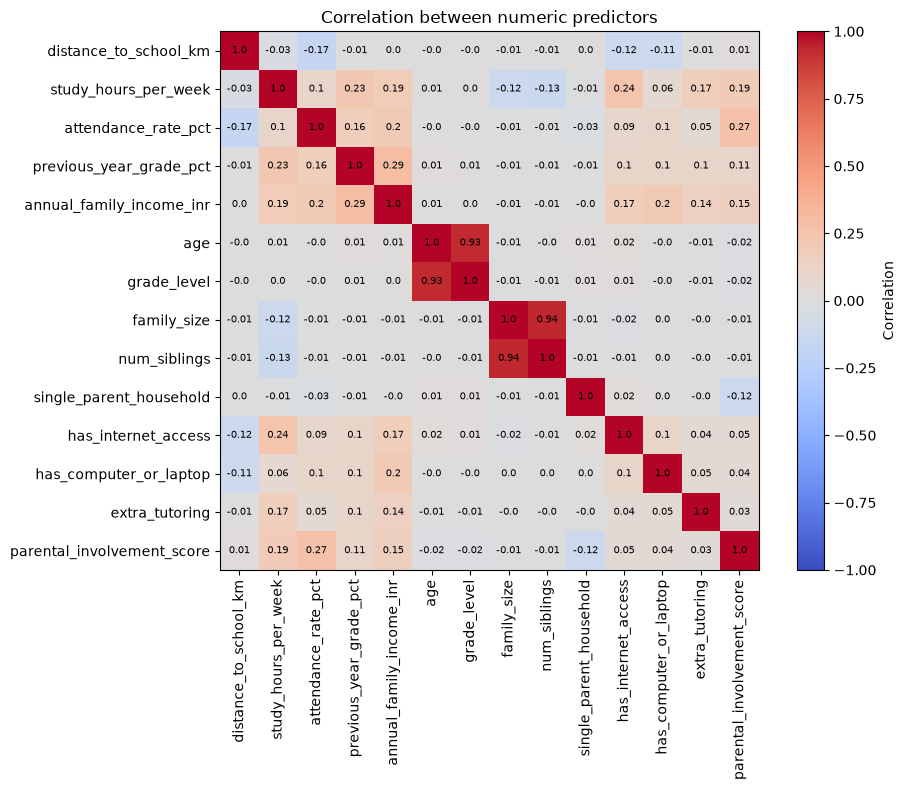

In [12]:
# Correlation heatmap of the numeric predictors
# (categorical columns are text, so they are left out here)
corr = X[NUMERIC_COLS].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)

# write the correlation value in each square
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=7)

plt.title('Correlation between numeric predictors')
plt.tight_layout()
plt.show()

From the heatmap, most predictors are only weakly correlated with each other. Two pairs stand out:

- `age` and `grade_level` (r = 0.93): students in the same grade are mostly the same age.
- `family_size` and `num_siblings` (r = 0.94): more siblings means a bigger family.

Keeping both columns of a pair gives the linear models the same information twice, which makes the OLS coefficients unstable. So we drop one column from each pair:

- Keep `grade_level`, drop `age`. Grade level tells us which curriculum the student is in, and age within a grade adds little.
- Keep `family_size`, drop `num_siblings`. Family size also counts parents and other relatives, so it is the more general measure.

Categorical vs Numeric Predictors ()

We also considered doing categorical vs numeric predictors but realised there is only one pair of high correlatio

In [53]:
# family_income_bracket is a banded version of annual_family_income_inr, so check how closely they match
bracket_rank = X['family_income_bracket'].map({'Low': 0, 'Lower-Middle': 1, 'Middle': 2, 'Upper-Middle': 3, 'High': 4})
log_income = np.log1p(X['annual_family_income_inr'])

print(f'Correlation between family_income_bracket and log income: r = {bracket_rank.corr(log_income):.2f}')

Correlation between family_income_bracket and log income: r = 0.96


In [ ]:
# Drop one predictor from each highly correlated pair
DROP_COLS = ['age', 'num_siblings']

DISCRETE_COLS   = [c for c in DISCRETE_COLS if c not in DROP_COLS]
NUMERIC_COLS    = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS  = NUMERIC_COLS + CATEGORICAL_COLS

X                = df[PREDICTOR_COLS]         # Shared predictors
Y_regression     = df[REGRESSION_TARGET]      # Regression target
Y_classification = df[CLASSIFICATION_TARGET]  # Classification target 

print('Dropped:', DROP_COLS)
print('X:', X.shape)

Dropped: ['age', 'num_siblings']
X: (12000, 22)


## Data Preprocessing: Data Preparation Pipelines

Data preparation for models that requires standardization, one-hot/ordinal encoding and data wrangling etc to prep data for later analysis. 

In [ ]:
# Setup helper functions for data preparation so that X-train and X-test can be massaged into a format palatable to each model 

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import BaseEstimator, RegressorMixin
from pygam import LinearGAM, s, l      
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
from scipy.stats import norm

# Columns with no natural order: one-hot encoded
ONEHOT_COLUMNS = ['gender', 'school_type', 'residence_type', 'academic_year',
                  'father_occupation', 'mother_occupation']

# Columns with a clear order (lowest level first): ordinal encoded
ORDINAL_COLUMNS = {
    'father_education_level': [
        'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
        "Bachelor's Degree", "Master's Degree", 'Doctorate',
    ],
    'mother_education_level': [
        'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
        "Bachelor's Degree", "Master's Degree", 'Doctorate',
    ],
    'scholarship_status': ['No Scholarship', 'Partial', 'Full'],
}

def build_prep(scale):
    # Logging for family income
    log_step = ColumnTransformer(
        [("log", log_transform(), ["annual_family_income_inr"])],
        verbose_feature_names_out=False,
        remainder="passthrough"
    ).set_output(transform="pandas")

    # one-hot and ordinal encoders are the same for every family. Only scaling differs
    # family_income_bracket is not listed, so it is dropped here (GroupImputer has already used it to fill income)
    scale_encode_step = ColumnTransformer([
        ('onehot',  OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ONEHOT_COLUMNS),
        ('ordinal', OrdinalEncoder(categories=list(ORDINAL_COLUMNS.values())), list(ORDINAL_COLUMNS)),
        ('num',     StandardScaler() if scale else 'passthrough', NUMERIC_COLS),
    ])

    return Pipeline([
        ("impute", GroupImputer()),
        ("log", log_step),
        ("scale", scale_encode_step)
    ])

def make_linear_prep():  # OLS, Ridge, Lasso
    return build_prep(scale=True)

def make_gam_prep():     # GAM: splines handle the shape, so no scaling
    return build_prep(scale=False)

class GAMRegressor(BaseEstimator, RegressorMixin):
    # Wrapper so pygam's LinearGAM works inside a Pipeline and GridSearchCV
    # Smooth spline term for each continuous column, linear term for every other column
    def __init__(self, n_splines=10, lam=0.6):
        self.n_splines = n_splines
        self.lam = lam      # smoothing penalty, bigger = smoother curves

    def fit(self, X, y):
        first_continuous = X.shape[1] - len(NUMERIC_COLS)   # one-hot and ordinal columns come first
        last_continuous = first_continuous + len(CONTINUOUS_COLS)
        terms = l(0)
        for j in range(1, X.shape[1]):
            if first_continuous <= j < last_continuous:
                terms = terms + s(j, n_splines=self.n_splines, lam=self.lam)
            else:
                terms = terms + l(j)
        self.gam_ = LinearGAM(terms).fit(X, y)
        return self

    def predict(self, X):
        return self.gam_.predict(X)

def make_knn_prep():     # KNN: distances need scaled columns
    return build_prep(scale=True)

def make_tree_prep():    # decision tree, bagging, random forest
    return build_prep(scale=False)

def make_gbt_prep():     # gradient boosting
    return build_prep(scale=False)

def make_svr_prep():     # SVM: RBF kernel uses distances, so scale
    return build_prep(scale=True)


## Data Preprocessing: Performance Test Metrics Helper Function

Setup respective performance metrics for upcoming regression and classification experiments. 

In [ ]:
# Performance Test Metrics 

# Regression
def compute_test_metrics(fitted_model, X_train, Y_train, X_test, Y_test, cv_folds):
    # Returns (RMSE, MAE, R2, CV RMSE, mean Gaussian log-likelihood) of a fitted model on the test set
    test_predictions = fitted_model.predict(X_test)
    # CV RMSE on the training data: from the grid search if tuned, otherwise 5-fold cross_val_score
    if hasattr(fitted_model, 'best_score_'):
        cv_rmse = -fitted_model.best_score_
    else:
        cv_rmse = -cross_val_score(fitted_model, X_train, Y_train, cv=cv_folds, scoring='neg_root_mean_squared_error').mean()
    # Likelihood uses the CV RMSE as the noise sd, so the test set is not used to choose it
    return (root_mean_squared_error(Y_test, test_predictions),
            mean_absolute_error(Y_test, test_predictions),
            r2_score(Y_test, test_predictions),
            cv_rmse,
            norm.logpdf(Y_test, loc=test_predictions, scale=cv_rmse).mean())


# Classification
def compute_classification_test_metrics(fitted_search, X_test, Y_test):
    # Returns (AUC, CV AUC) of a fitted grid search on the test set
    # The test AUC uses the same roc_auc scoring as the tuning, and the CV AUC comes from the tuning on the training data
    return (fitted_search.score(X_test, Y_test),
            fitted_search.best_score_)


# Main Experiment

In our experiment, we will be performing regression and classification prediction analysis according to the target columns defined. (Regression: `final_grade_pct`, Classification: `at_risk_flag`).

In the context of the schooling administration, what we would like to understand is what are the strongest predictors for student scores and grades. Beyond obvious predictors such as previous grade scores, are there other classes of predictors such as socioeconomic factors or technology access that help to predict student performance? 

In answering this question, we explore which model has stronger predictive performance and understand the nature of the underlying data (linear vs. nonlinear relationship). 

Practical Application: While regression analysis provides a fuller analysis on the underlying data, a school may care more about a practical question such as "which predictors are useful in identifying at-risk students?" than about an exact score percentage. Classification measures this directly, and lets us check whether the conclusions from the regression experiment still hold for the students most likely to fail.

---

It is important to note that it is possible to infer classification target, `at_risk_flag`, directly from our regression target, `final_grade_pct`, because the flag is simply a cut-off on the final grade:

| `at_risk_flag` | `final_grade_pct` |
|---|---|
| 1 (at risk) | below 40 | 
| 0 (not at risk) | 40 to 100 | 

Because both experiments are predicting the same outcome at different levels of detail (granularity), the classification results are not independent evidence. Regression is the main experiment as it's the fuller version of the problem. Classification reduces the same outcome to a single cut-off and so the results are coarser (as the cut-off loses information). However, the classification experiment is valuable for us to understand tail-end at-risk students better. 

## Stage 1: Hyperparameter Tuning Pilot Run: Coarse-to-Fine Search
The upcoming main regression experiment below repeats a full grid search 20 times, so searching a large grid each time would be computationally expensive (curse of dimensionality). 

To reduce this cost, a coarse-to-fine search is used: a one-off search over a wide, roughly log-spaced grid of values for each model, evaluated with 5-fold cross-validation on the training data only. The best value and its neighbours form a narrower grid, which the main experiment uses for its tuning.

The pilot runs model searches concurrently using a `ThreadPoolExecutor`, with at most `MAX_CONCURRENT_PILOT_MODELS` searches at once (default: 4). Each search and estimator uses one job, with native library threads limited during the pool run. Results are collected in model order, and plots are generated on the main thread after all searches finish.


In [ ]:
from concurrent.futures import ThreadPoolExecutor
from threadpoolctl import threadpool_limits

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

X_pilot, _, Y_pilot, _ = train_test_split(X, Y_regression, test_size=0.15, random_state=0, shuffle=True)
pilot_cv = KFold(n_splits=5, shuffle=True, random_state=0)

# Bound the number of model searches running at once.
MAX_CONCURRENT_PILOT_MODELS = 4

# Wide grids
wide_ridge_grid         = {'model__alpha':            [0.1, 1, 3, 10, 30, 100, 300, 1000, 3000]}
wide_lasso_grid         = {'model__alpha':            [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]}
wide_gam_grid           = {'model__lam':              [0.1, 1, 10, 100, 1000]}
wide_knn_grid           = {'model__n_neighbors':      [5, 10, 25, 50, 100, 200, 400],
                           'model__weights':          ['uniform', 'distance']}
wide_decision_tree_grid = {'model__max_depth':        [2, 3, 4, 6, 8, 10, 15],
                           'model__min_samples_leaf': [5, 10, 20, 50, 100, 200, 400]}
wide_random_forest_grid = {'model__max_features':     [0.1, 0.2, 0.33, 0.5, 0.8, 1.0],
                           'model__min_samples_leaf': [1, 5, 10, 20, 40, 80]}
wide_gbt_grid           = {'model__learning_rate':    [0.01, 0.02, 0.05, 0.1, 0.2, 0.4],
                           'model__max_depth':        [1, 2, 3, 4, 6],
                           'model__min_samples_leaf': [10, 20, 50, 100, 200]}

# Name: (pipeline, wide grid)
pilot_models = {
    'Ridge':          (Pipeline([('prep', make_linear_prep()), ('model', Ridge())]),                                                                          wide_ridge_grid),
    'Lasso':          (Pipeline([('prep', make_linear_prep()), ('model', Lasso(max_iter=10000))]),                                                            wide_lasso_grid),
    'GAM':            (Pipeline([('prep', make_gam_prep()),    ('model', GAMRegressor())]),                                                                   wide_gam_grid),
    'k-NN':           (Pipeline([('prep', make_knn_prep()),    ('model', KNeighborsRegressor(n_jobs=1))]),                                                    wide_knn_grid),
    'Decision tree':  (Pipeline([('prep', make_tree_prep()),   ('model', DecisionTreeRegressor(random_state=0))]),                                            wide_decision_tree_grid),
    'Random forest':  (Pipeline([('prep', make_tree_prep()),   ('model', RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=1))]),                wide_random_forest_grid),
    'GBT':            (Pipeline([('prep', make_gbt_prep()),    ('model', HistGradientBoostingRegressor(max_iter=500, early_stopping=True, random_state=0))]), wide_gbt_grid),
}

def narrow(values, best_value):
    # keep the best value and one neighbour on each side
    i = values.index(best_value)
    return values[max(i - 1, 0): i + 2]

pilot_results = {}
best_values   = {}
final_grids   = {}

def run_pilot_search(pipe, grid):
    # Parallelism is across models; each search uses a single sklearn job.
    search = GridSearchCV(pipe, grid, cv=pilot_cv,
                          scoring='neg_root_mean_squared_error', n_jobs=1)
    search.fit(X_pilot, Y_pilot)
    return search.cv_results_, search.best_params_, search.best_score_


# Keep native library threads bounded while searches run concurrently.
with threadpool_limits(limits=3):
    with ThreadPoolExecutor(max_workers=MAX_CONCURRENT_PILOT_MODELS) as executor:
        pilot_futures = {
            name: executor.submit(run_pilot_search, pipe, grid)
            for name, (pipe, grid) in pilot_models.items()
        }
        # Collect and print in model order; worker failures propagate through result().
        for name, (_, grid) in pilot_models.items():
            cv_results, best_params, best_score = pilot_futures[name].result()
            pilot_results[name] = pd.DataFrame(cv_results)
            best_values[name]   = best_params
            final_grids[name]   = {}

            print(f'{name}: best CV RMSE = {-best_score:.3f}')
            for param, values in grid.items():
                best = best_params[param]
                if isinstance(values[0], str):      # text options (weights) are kept as they are
                    final_grids[name][param] = values
                else:
                    final_grids[name][param] = narrow(values, best)
                edge = '<-- on the edge of the wide grid' if best in (values[0], values[-1]) and not isinstance(best, str) else ''
                print(f'{param}: best = {best}, final grid = {final_grids[name][param]}{edge}')


# ==================================================================================================        
# Plotting: Red dashed line = best value, green band = values passed on to the main script

def plot_pilot_curve(ax, name, param, tried_values):
    scores = pilot_results[name].groupby('param_' + param)['mean_test_score'].max()
    rmse = -scores
    ax.plot(rmse.index.astype(float), rmse.values, marker='o')
    final_values = final_grids[name][param]
    ax.axvspan(min(final_values), max(final_values), color='green', alpha=0.2)
    ax.axvline(best_values[name][param], color='red', linestyle='--')

    # Use a log axis when the tried values cover a wide range
    if max(tried_values) / min(tried_values) > 20:
        ax.set_xscale('log')

    ax.set_xlabel(param.split('__')[-1])
    ax.set_ylabel('CV RMSE')
    ax.set_title(name)


for name, (pipe, grid) in pilot_models.items():
    # Text options (k-NN weights) cannot go on a number line, so skip them
    numeric_params = [param for param, values in grid.items() if not isinstance(values[0], str)]

    fig, axes = plt.subplots(1, len(numeric_params), figsize=(5 * len(numeric_params), 3.5))
    axes = np.atleast_1d(axes)      # with one plot, subplots returns a single axis instead of an array

    for ax, param in zip(axes, numeric_params):
        plot_pilot_curve(ax, name, param, grid[param])

    plt.tight_layout()
    plt.show()

### Limitation: Minor leakage from the hyperparameter pilot

The coarse-to-fine pilot runs once on a single 85% training split to narrow each regression model's grid. The main experiment then uses a different random split in each repeat, so on average about 85% of the rows in each later test set were already used by the pilot.

We expect the leakage effect to be small because:

- The pilot only decides the short list of hyperparameter values each model can choose from. Within each repeat, tuning, preprocessing and fitting still use only that repeat's 85% training data, so a model is never fitted on its own test rows.
- Any optimism can only favour the tuned models. Naive and OLS have no hyperparameters, so they are not affected.
- The classification experiment has no pilot, so it is not affected.

Reserving separate rows only for the pilot would remove the leak, but would leave less data for all 20 repeats. We keep the current setup and report this as a limitation.


## Stage 2: Regression Experiment 

**Experiment Setup:**

The regression experiment repeats the following steps 20 times for statistical comparison, using a different random 85/15 train-test split each time:

1. Split the train/test data. Every model in a repeat uses the same baseline train/test split, so we can compare models on paired differences.
2. Tune each model's hyperparameters (already based on the narrow range from hyperparameter pilot above) by cross-validation on the 85% training data (5-fold for every model). 
3. Score the tuned model on the 15% test data, which was not used for fitting or tuning.

**Pipeline:**

Imputation, encoding and scaling are all part of each model's pipeline, so they are learned from the training data with no leakage from test set. 

**Concurrent Runs:**
Within each repeat, models are fitted and scored concurrently using a `ThreadPoolExecutor`, limited by `MAX_CONCURRENT_MODELS` (default: 4). Grid searches and estimators use one job each, and native BLAS/OpenMP threads are limited during the pool run to avoid nested parallelism. Repeats run sequentially, with results collected in model order to preserve paired comparisons.


In [ ]:
# Main Regression Experiment

import time
from concurrent.futures import ThreadPoolExecutor
from threadpoolctl import threadpool_limits

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.inspection import permutation_importance

# Store (RMSE, MAE, R2, CV RMSE, log-likelihood) on the test set for each iteration, one tuple per loop
errors_naive                = []
errors_ols                  = []
errors_ridge                = []
errors_lasso                = []
errors_gam                  = []
errors_k_nearest_neighbors  = []
errors_decision_tree        = []
errors_random_forest        = []
errors_gradient_boosting    = []

# Feature importance collected in every experiment, so the feature selection section can report a mean and spread
importance_records        = []   # one row per (experiment, model): permutation importance of every predictor on that experiment's test set
lasso_selection_records   = []   # one row per experiment: True if the Lasso kept the predictor (any encoded column non-zero)
lasso_coefficient_records = []   # one row per experiment: the tuned Lasso's coefficient for every encoded column

def predictor_of(encoded_name):
    # 'onehot__father_occupation_Unemployed' -> 'father_occupation'
    stripped = encoded_name.split('__', 1)[1]
    return max((p for p in PREDICTOR_COLS if stripped == p or stripped.startswith(p + '_')), key=len)


def fit_and_score(model, X_train, Y_train, X_test, Y_test, cv_folds):
    # Each worker owns its model; result lists are updated by the main thread only.
    model.fit(X_train, Y_train)
    return compute_test_metrics(model, X_train, Y_train, X_test, Y_test, cv_folds)


# CONST HELPERS
TEST_SIZE              = 0.15   # 85/15 train/test split
NUMBER_OF_EXPERIMENTS  = 20     # Each experiment = new random 85/15 split, tune every model, score on the test set. 20 runs for rigorous statistical difference analysis

# Run models concurrently within each split; keep experiments sequential for paired results.
MAX_CONCURRENT_MODELS = 4      # Lower this if CPU or memory use is too high.

# HYPERPARAMETERS: come from the pilot cell above (run it first).
ridge_grid         = final_grids['Ridge']
lasso_grid         = final_grids['Lasso']
gam_grid           = final_grids['GAM']
knn_grid           = final_grids['k-NN']
decision_tree_grid = final_grids['Decision tree']
random_forest_grid = final_grids['Random forest']
gbt_grid           = final_grids['GBT']

for experiment in range(NUMBER_OF_EXPERIMENTS):

    # Step 1. 85/15 train/test split: standardized baseline for model comparison across models for this experiment
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y_regression, test_size=TEST_SIZE, random_state=experiment, shuffle=True)
    experiment_start_time = time.time()
    print('train:', X_train.shape, ' test:', X_test.shape)

    # Step 2. Model-specific pre-processing (one-hot/ordinal encoding, standardization etc.)
    # Each pipeline chains a preprocessor with a final model, so it can be fitted and used to predict directly
    naive_pipe               = Pipeline([('prep', make_linear_prep()), ('model', DummyRegressor(strategy='mean'))])                                                                                          # Linear: naive mean
    ols_pipe                 = Pipeline([('prep', make_linear_prep()), ('model', LinearRegression(n_jobs=1))])                                                                                                       # Linear: OLS
    ridge_pipe               = Pipeline([('prep', make_linear_prep()), ('model', Ridge())])                                                                                                                  # Linear: Ridge
    lasso_pipe               = Pipeline([('prep', make_linear_prep()), ('model', Lasso(max_iter=10000))])                                                                                                    # Linear: Lasso
    gam_pipe                 = Pipeline([('prep', make_gam_prep()),    ('model', GAMRegressor())])                                                                                                           # GAM
    k_nearest_neighbors_pipe = Pipeline([('prep', make_knn_prep()),    ('model', KNeighborsRegressor(n_jobs=1))])                                                                                                    # k-NN
    decision_tree_pipe       = Pipeline([('prep', make_tree_prep()),   ('model', DecisionTreeRegressor(random_state=experiment))])                                                                           # Decision tree
    random_forest_pipe       = Pipeline([('prep', make_tree_prep()),   ('model', RandomForestRegressor(n_estimators=100, random_state=experiment, n_jobs=1))])                                              # Random forest
    gradient_boosting_pipe   = Pipeline([('prep', make_gbt_prep()),    ('model', HistGradientBoostingRegressor(max_iter=500, early_stopping=True, random_state=experiment))])                                # Boosting / GBT

    # Step 3. GridSearchCV - K-folds on 85% training data with aim of finding the best hyperparameters.
    cv = KFold(n_splits=5, shuffle=True, random_state=experiment)
    scoring = 'neg_root_mean_squared_error'

    # Define the grid searches
    ridge_search                = GridSearchCV(ridge_pipe,               ridge_grid,         cv=cv,               scoring=scoring, n_jobs=1)
    lasso_search                = GridSearchCV(lasso_pipe,               lasso_grid,         cv=cv,               scoring=scoring, n_jobs=1)
    gam_search                  = GridSearchCV(gam_pipe,                 gam_grid,           cv=cv,               scoring=scoring, n_jobs=1)
    k_nearest_neighbors_search  = GridSearchCV(k_nearest_neighbors_pipe, knn_grid,           cv=cv,               scoring=scoring, n_jobs=1)
    decision_tree_search        = GridSearchCV(decision_tree_pipe,       decision_tree_grid, cv=cv,               scoring=scoring, n_jobs=1)
    random_forest_search        = GridSearchCV(random_forest_pipe,       random_forest_grid, cv=cv, scoring=scoring, n_jobs=1)
    gradient_boosting_search    = GridSearchCV(gradient_boosting_pipe,   gbt_grid,           cv=cv,               scoring=scoring, n_jobs=1)

    # Steps 4 and 5. Fit and evaluate models in a bounded thread pool.
    # GridSearchCV objects predict with their best refitted pipeline.
    fitted_models = [
        (naive_pipe,                 errors_naive),
        (ols_pipe,                   errors_ols),
        (ridge_search,               errors_ridge),
        (lasso_search,               errors_lasso),
        (gam_search,                 errors_gam),
        (k_nearest_neighbors_search, errors_k_nearest_neighbors),
        (decision_tree_search,       errors_decision_tree),
        (random_forest_search,       errors_random_forest),
        (gradient_boosting_search,   errors_gradient_boosting)
    ]

    # Limit native BLAS/OpenMP threads as well as sklearn jobs to avoid nested parallelism.
    with threadpool_limits(limits=3):
        with ThreadPoolExecutor(max_workers=MAX_CONCURRENT_MODELS) as executor:
            futures = [
                executor.submit(fit_and_score, model, X_train, Y_train, X_test, Y_test, cv)
                for model, _ in fitted_models
            ]
            # Read results in model order; result() also propagates worker failures.
            for future, (_, error_list) in zip(futures, fitted_models):
                error_list.append(future.result())

    # Step 5b. Feature importance of the tuned models on this experiment's test set
    for importance_name, importance_search in [('Lasso', lasso_search), ('DT', decision_tree_search),
                                               ('RF', random_forest_search), ('GBT', gradient_boosting_search)]:
        result = permutation_importance(importance_search.best_estimator_, X_test, Y_test,
                                        scoring='neg_root_mean_squared_error', n_repeats=5, random_state=experiment)
        importance_records.append({'experiment': experiment, 'model': importance_name,
                                   **dict(zip(PREDICTOR_COLS, result.importances_mean))})

    # Predictors the tuned Lasso kept in this experiment
    lasso_best = lasso_search.best_estimator_
    lasso_coefficients = pd.Series(lasso_best.named_steps['model'].coef_, index=lasso_best.named_steps['prep'].get_feature_names_out())
    kept_predictors = {predictor_of(name) for name in lasso_coefficients.index[lasso_coefficients != 0]}
    lasso_selection_records.append({'experiment': experiment, **{p: p in kept_predictors for p in PREDICTOR_COLS}})
    lasso_coefficient_records.append({'experiment': experiment, **lasso_coefficients.to_dict()})

    print(f'experiment {experiment + 1}/{NUMBER_OF_EXPERIMENTS} done in {time.time() - experiment_start_time:.0f}s')


## Model Performance Metrics 

The following metrics apply to all nine regression models:

- **RMSE**: typical error size, penalises large errors (also the tuning criterion)
- **MAE**: average absolute error, less sensitive to outliers
- **CV RMSE**: RMSE from the k-fold tuning on the 85% training data (`best_score_`; 5-fold `cross_val_score` for naive and OLS). Compared with the test RMSE, it shows how well tuning predicts test performance
- **R2**: share of variance explained versus predicting the mean (the naive model is about 0)
- **Gaussian test log-likelihood (MLE)**: mean of log N(y; prediction, sigma^2) over the test set, higher is better. Sigma is the CV RMSE on the training data. With Gaussian errors this is a decreasing function of MSE, so it ranks models like RMSE unless the sigmas differ


## Regression Performance Analysis: Box plots and confidence intervals

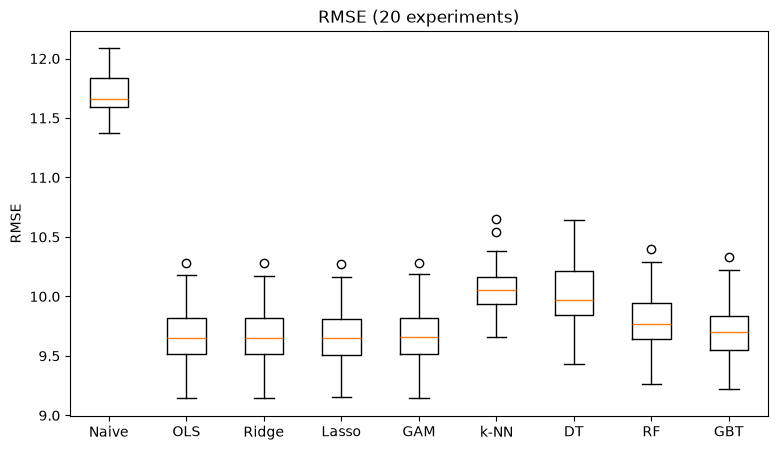

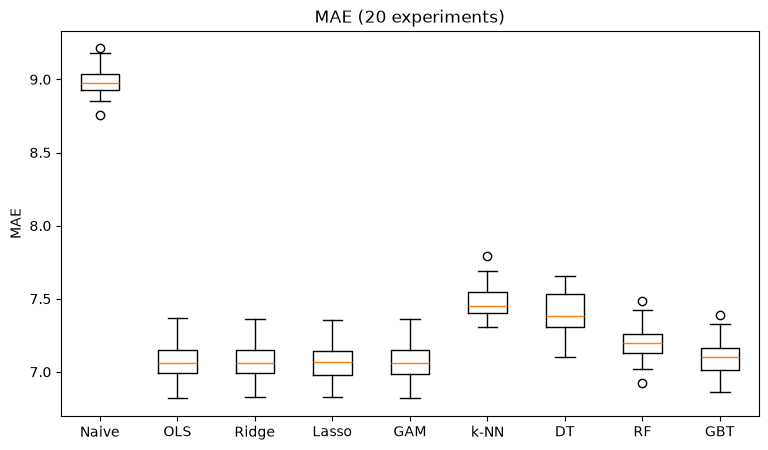

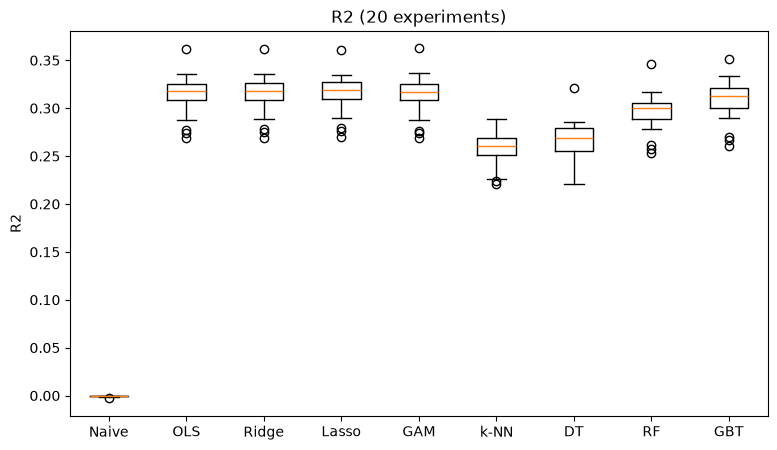

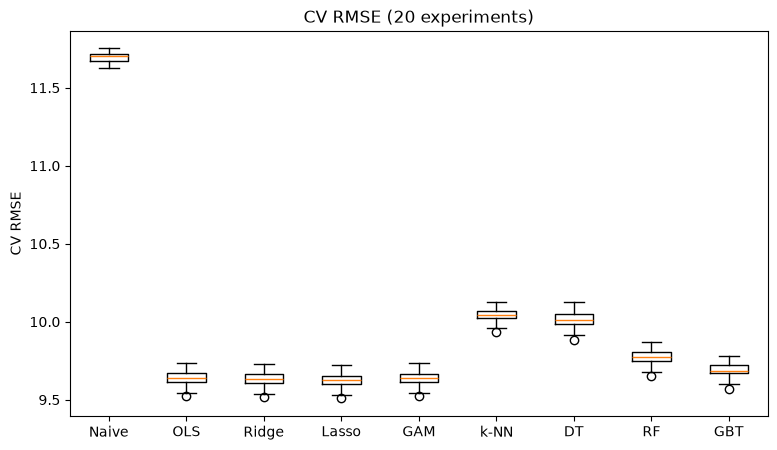

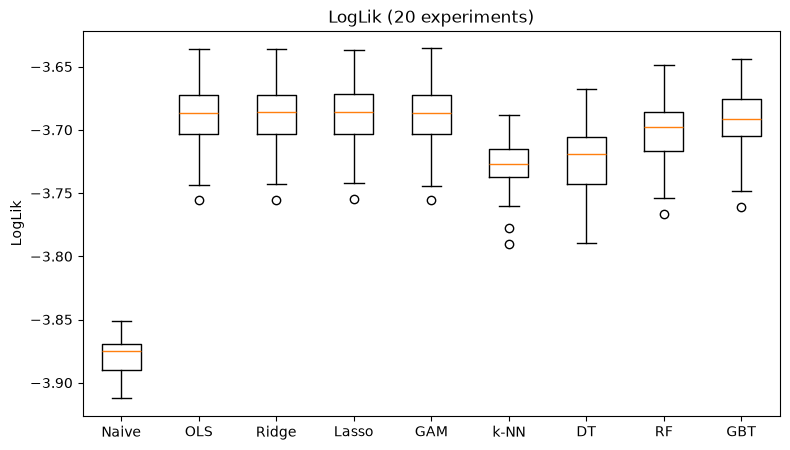

In [58]:
names = ['Naive', 'OLS', 'Ridge', 'Lasso', 'GAM', 'k-NN', 'DT', 'RF', 'GBT']
model_error_lists = [errors_naive, errors_ols, errors_ridge, errors_lasso, errors_gam,
                     errors_k_nearest_neighbors, errors_decision_tree, errors_random_forest, errors_gradient_boosting]

# each loop stores (RMSE, MAE, R2, CV RMSE, LogLik), so column 0 to 4 is one measure
for col, metric in enumerate(['RMSE', 'MAE', 'R2', 'CV RMSE', 'LogLik']):
    plt.figure(figsize=(9, 5))
    plt.boxplot([np.array(e)[:, col] for e in model_error_lists])
    plt.xticks(range(1, len(names) + 1), names)
    plt.ylabel(metric)
    plt.title(f'{metric} ({NUMBER_OF_EXPERIMENTS} experiments)')
    plt.show()


### Regression Performance Analysis: Actual vs. predicted grades

Each panel shows held-out test predictions from the **final repeat** of the regression experiment. Actual final grade is on the x-axis and predicted final grade is on the y-axis; every model uses the same test students. The dashed diagonal represents perfect predictions. Points above it are overpredictions, and points below it are underpredictions. All panels use the same scale, including predictions outside 0-100 if present.


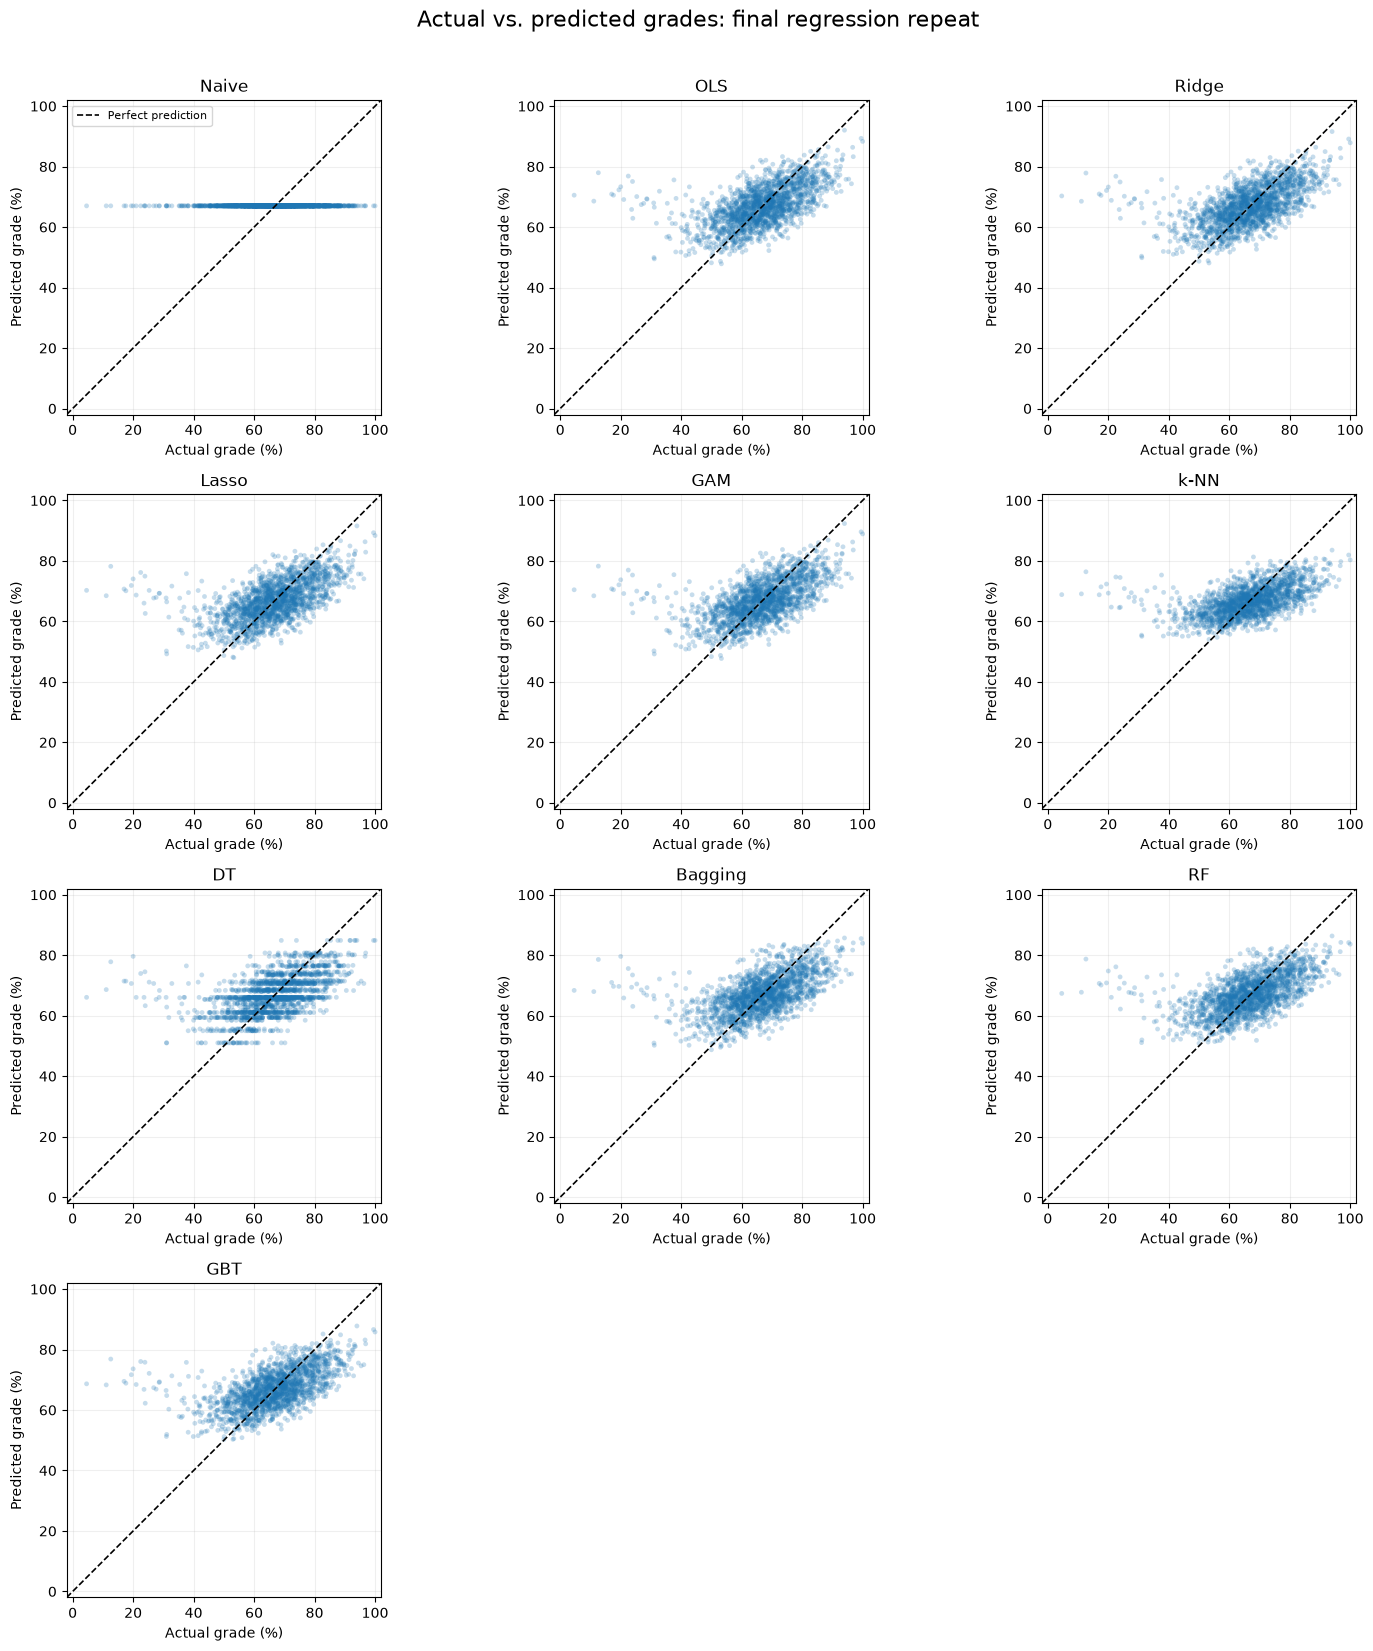

In [19]:
# Use the final repeat's fitted models and held-out test data; no refitting.
regression_plot_models = {
    'Naive': naive_pipe,
    'OLS': ols_pipe,
    'Ridge': ridge_search,
    'Lasso': lasso_search,
    'GAM': gam_search,
    'k-NN': k_nearest_neighbors_search,
    'DT': decision_tree_search,
    'RF': random_forest_search,
    'GBT': gradient_boosting_search,
}
actual_grades = np.asarray(Y_test, dtype=float)
regression_plot_predictions = {
    name: np.asarray(model.predict(X_test), dtype=float)
    for name, model in regression_plot_models.items()
}

# Shared limits and equal aspect make distances from the diagonal comparable.
all_grades = np.concatenate([actual_grades, *regression_plot_predictions.values()])
grade_min = min(0, all_grades.min())
grade_max = max(100, all_grades.max())
padding = 0.02 * (grade_max - grade_min)
grade_limits = (grade_min - padding, grade_max + padding)

ncols = 3
nrows = (len(regression_plot_models) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.2 * nrows),
                         sharex=True, sharey=True, squeeze=False)
for ax, (name, predicted_grades) in zip(axes.flat, regression_plot_predictions.items()):
    ax.scatter(actual_grades, predicted_grades, s=12, alpha=0.25,
               edgecolors='none', rasterized=True)
    ax.plot(grade_limits, grade_limits, color='black', linestyle='--',
            linewidth=1.2, label='Perfect prediction')
    ax.set_title(name)
    ax.set_xlabel('Actual grade (%)')
    ax.set_ylabel('Predicted grade (%)')
    ax.tick_params(labelbottom=True, labelleft=True)
    ax.set_xlim(grade_limits)
    ax.set_ylim(grade_limits)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

axes.flat[0].legend(fontsize=8)
for ax in axes.flat[len(regression_plot_models):]:
    ax.set_visible(False)

fig.suptitle('Actual vs. predicted grades: final regression repeat',
             fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


### Regression Performance Analysis: Paired t-tests

We want to know if the best model (the one with the lowest mean test RMSE) is really better than each of the other models, or if the difference could just be noise from the random train/test splits.

Every model uses the same 20 train/test splits, so we can compare two models split by split. This is why we use a paired t-test on the differences in RMSE.

The paired t-test from the labs (`ttest_rel`) assumes the 20 splits are independent. Ours are not, because they all come from the same students and so the splits overlap. This makes the basic test too confident. To fix this, we use the correction from Nadeau and Bengio (2003), which makes the standard error larger:

se = sqrt((1/N + n_test/n_train) * var(diff)), with N - 1 degrees of freedom

For our setup (N = 20 and an 85/15 split), the standard error is about 2.1 times larger than in the basic test.

How we read the results:

- A small p-value means the best model is better than that model by more than we would expect from noise.
- A large p-value means we cannot tell the two models apart. It does not prove that they are equally good.
- We picked the best model using the same test results, and we did not adjust for making eight comparisons, so the p-values are only exploratory.

In [21]:
from scipy.stats import t as t_distribution, ttest_rel

def corrected_ttest(a, b):
    # Same as ttest_rel, but corrected because the splits overlap (Nadeau & Bengio, 2003)
    n = len(a)
    t_stat = ttest_rel(a, b).statistic * np.sqrt((1 / n) / (1 / n + TEST_SIZE / (1 - TEST_SIZE)))
    return t_stat, 2 * t_distribution.sf(abs(t_stat), df=n - 1)

rmse = {name: np.array(errors)[:, 0] for name, errors in zip(names, model_error_lists)}
best = min(rmse, key=lambda name: rmse[name].mean())
print('Best model on RMSE:', best)

for name in rmse:
    if name != best:
        t_stat, p = corrected_ttest(rmse[name], rmse[best])
        print(f'{name:8} mean diff = {(rmse[name] - rmse[best]).mean():.3f}   t = {t_stat:.2f}   p = {p:.4f}')

Best model on RMSE: Lasso
Naive    mean diff = 2.017   t = 30.51   p = 0.0000
OLS      mean diff = 0.008   t = 1.95   p = 0.0665
Ridge    mean diff = 0.006   t = 2.23   p = 0.0381
GAM      mean diff = 0.008   t = 1.82   p = 0.0851
k-NN     mean diff = 0.395   t = 14.30   p = 0.0000
DT       mean diff = 0.335   t = 12.40   p = 0.0000
Bagging  mean diff = 0.134   t = 5.81   p = 0.0000
RF       mean diff = 0.132   t = 6.34   p = 0.0000
GBT      mean diff = 0.044   t = 3.16   p = 0.0052


### Regression Performance Analysis: Conclusion (TODO: complete after the final run)

**TODO: every value in [square brackets] must be filled in from the final t-test output, and each sentence checked against it. The model groupings below are what an earlier partial run suggested, not final results. Delete this line when done.**

**Which model performs best?** [Best model] has the lowest mean test RMSE, at [x] grade points (R2 = [x]), compared with [x] grade points for the Naive baseline. The predictors therefore carry real signal, but they explain only about [x]% of the variation in final grades, so most of the differences between students are not captured by this data.

**Is there evidence of nonlinearity?** [Best model] is not statistically distinguishable from [OLS, Ridge and the GAM], and it has significantly lower RMSE than [k-NN, the decision tree, random forest and gradient boosting]. The GAM can fit curved effects but does not improve on the linear models, and the more flexible models do no better than them. We therefore find no evidence that strong nonlinear effects or interactions are needed to predict final grades from these predictors.

**What is the price of interpretability?** [OLS / Lasso] gives directly interpretable coefficients at a cost of [x] RMSE compared with the best model, which is [not statistically significant]. We would therefore recommend [OLS / Lasso] for this task.

**How far can we rely on this?** The models that cannot be separated from [Best model] are not shown to be equal, only that the test cannot detect a difference between them. The p-values are exploratory: the best model was chosen on the same test results, the overlap correction is approximate, and the eight comparisons are not adjusted for multiple testing. Linear models matching or beating flexible models is also unusual on real tabular data, and may reflect how this dataset was constructed, so we do not claim that the same would hold for other student populations.

## Stage 3: Classification Experiment

**Motivation**
The predicted vs. actual grade plots show particularly poor regression performance for F-grade students (final grade below 40). Many of the largest prediction errors occur among students with low actual grades. If our goal is to identify students at risk of failing so that they can receive support, we can approach this as a classification problem, predicting `at_risk_flag` directly.


**How the experiment is setup**

The classification experiment predicts `at_risk_flag` (1 = final grade below 40) from the same predictors as the regression experiment. It repeats the following steps 20 times for statistical comparison, using a different random 85/15 train/test split each time:

1. Split the train/test data, stratified by `at_risk_flag` so that the rare at-risk students (219 of 12,025, about 1.8%) appear in every split in the same proportion. Every model in a repeat uses the same train/test split, so we can compare models on paired differences.
2. Tune each model's hyperparameters by 5-fold stratified cross-validation on the 85% training data only, choosing the settings with the best AUC. As classification is a supporting analysis, we did not run a separate pilot experiment and each model is tuned over a small grid directly.
3. Score the tuned model on the 15% test data, which was not used for fitting or tuning.

Imputation, encoding and scaling are all part of each model's pipeline, so they are also learned from the training data only.

In [60]:
# Main Classification Experiment (target: at_risk_flag)
import time
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import BaggingClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier


classification_results = []
classification_names   = ['Naive', 'Logistic L2', 'Logistic L1', 'DT', 'Bagging', 'RF', 'GBT', 'k-NN', 'SVM']

# HYPERPARAMETERS: small grids chosen directly, as classification has no pilot experiment
logistic_l2_class_grid         = {'model__C': [0.01, 0.1, 1.0, 10.0]}
logistic_l1_class_grid         = {'model__C': [0.01, 0.1, 1.0, 10.0]}
decision_tree_class_grid       = {'model__min_samples_leaf': [10, 30]}
bagging_class_grid             = {'model__max_samples': [0.7, 1.0]}
random_forest_class_grid       = {'model__max_features': [0.5, 1.0]}
gradient_boosting_class_grid   = {'model__learning_rate': [0.05, 0.1], 'model__max_depth': [1, 3]}
k_nearest_neighbors_class_grid = {'model__n_neighbors': [15, 45],      'model__weights': ['uniform', 'distance']}
svm_class_grid                 = {'model__C': [0.1, 1.0, 10.0]}

for experiment in range(NUMBER_OF_EXPERIMENTS):
    # Step 1. Stratified train/test split shared by all classifiers
    X_train_class, X_test_class, Y_train_class, Y_test_class = train_test_split(
        X, Y_classification, test_size=TEST_SIZE,
        stratify=Y_classification, random_state=experiment
    )
    experiment_start_time = time.time()

    # Step 2. Set up model-specific preprocessing and classifiers
    naive_class_pipe               = Pipeline([('prep', make_tree_prep()),   ('model', DummyClassifier(strategy='most_frequent'))])
    logistic_l2_class_pipe         = Pipeline([('prep', make_linear_prep()), ('model', LogisticRegression(l1_ratio=0, max_iter=5000))])
    logistic_l1_class_pipe         = Pipeline([('prep', make_linear_prep()), ('model', LogisticRegression(l1_ratio=1, solver='saga', max_iter=5000))])
    decision_tree_class_pipe       = Pipeline([('prep', make_tree_prep()),   ('model', DecisionTreeClassifier(random_state=experiment))])
    bagging_class_pipe             = Pipeline([('prep', make_tree_prep()),   ('model', BaggingClassifier(n_estimators=50, random_state=experiment, n_jobs=-1))])
    random_forest_class_pipe       = Pipeline([('prep', make_tree_prep()),   ('model', RandomForestClassifier(n_estimators=100, random_state=experiment, n_jobs=-1))])
    gradient_boosting_class_pipe   = Pipeline([('prep', make_gbt_prep()),    ('model', HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=experiment))])
    k_nearest_neighbors_class_pipe = Pipeline([('prep', make_knn_prep()),    ('model', KNeighborsClassifier())])
    svm_class_pipe                 = Pipeline([('prep', make_svr_prep()),    ('model', SVC(kernel='rbf'))])

    # Step 3. GridSearchCV - stratified K-folds on 85% training data with aim of finding the best hyperparameters
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=experiment)
    scoring = 'roc_auc'

    # Define the grid searches (Naive has no hyperparameters, it is in a search so that it gets the same AUC scoring)
    naive_class_search               = GridSearchCV(naive_class_pipe,               {},                             cv=cv, scoring=scoring)
    logistic_l2_class_search         = GridSearchCV(logistic_l2_class_pipe,         logistic_l2_class_grid,         cv=cv, scoring=scoring)
    logistic_l1_class_search         = GridSearchCV(logistic_l1_class_pipe,         logistic_l1_class_grid,         cv=cv, scoring=scoring)
    decision_tree_class_search       = GridSearchCV(decision_tree_class_pipe,       decision_tree_class_grid,       cv=cv, scoring=scoring, n_jobs=-1)
    bagging_class_search             = GridSearchCV(bagging_class_pipe,             bagging_class_grid,             cv=cv, scoring=scoring)
    random_forest_class_search       = GridSearchCV(random_forest_class_pipe,       random_forest_class_grid,       cv=cv, scoring=scoring)
    gradient_boosting_class_search   = GridSearchCV(gradient_boosting_class_pipe,   gradient_boosting_class_grid,   cv=cv, scoring=scoring)
    k_nearest_neighbors_class_search = GridSearchCV(k_nearest_neighbors_class_pipe, k_nearest_neighbors_class_grid, cv=cv, scoring=scoring, n_jobs=-1)
    svm_class_search                 = GridSearchCV(svm_class_pipe,                 svm_class_grid,                 cv=cv, scoring=scoring, n_jobs=-1)

    # Fit everything on the 85% training data
    naive_class_search.fit(X_train_class, Y_train_class)
    logistic_l2_class_search.fit(X_train_class, Y_train_class)
    logistic_l1_class_search.fit(X_train_class, Y_train_class)
    decision_tree_class_search.fit(X_train_class, Y_train_class)
    bagging_class_search.fit(X_train_class, Y_train_class)
    random_forest_class_search.fit(X_train_class, Y_train_class)
    gradient_boosting_class_search.fit(X_train_class, Y_train_class)
    k_nearest_neighbors_class_search.fit(X_train_class, Y_train_class)
    svm_class_search.fit(X_train_class, Y_train_class)

    # Step 4. Evaluate best chosen hyperparameter for each model on the 15% testing data set
    # GridSearchCV objects predict with their best refitted pipeline
    fitted_class_models = [
        ('Naive',       naive_class_search),
        ('Logistic L2', logistic_l2_class_search),
        ('Logistic L1', logistic_l1_class_search),
        ('DT',          decision_tree_class_search),
        ('Bagging',     bagging_class_search),
        ('RF',          random_forest_class_search),
        ('GBT',         gradient_boosting_class_search),
        ('k-NN',        k_nearest_neighbors_class_search),
        ('SVM',         svm_class_search)
    ]

    # Step 5. Record AUC for this iteration
    for name, search in fitted_class_models:
        test_auc, cv_auc = compute_classification_test_metrics(search, X_test_class, Y_test_class)
        classification_results.append({
            'experiment': experiment + 1, 'model': name, 'CV AUC': cv_auc,
            'train size': len(X_train_class), 'test size': len(X_test_class),
            'AUC': test_auc,
            'best parameters': search.best_params_,
        })
    print(f'experiment {experiment + 1}/{NUMBER_OF_EXPERIMENTS} done in {time.time() - experiment_start_time:.0f}s')

# Summarise results across experiments
classification_results = pd.DataFrame(classification_results)
classification_summary = classification_results.groupby('model')[['CV AUC', 'AUC']].agg(['mean', 'std']).reindex(classification_names)


experiment 1/20 done in 29s
experiment 2/20 done in 29s
experiment 3/20 done in 28s
experiment 4/20 done in 29s
experiment 5/20 done in 28s
experiment 6/20 done in 30s
experiment 7/20 done in 27s
experiment 8/20 done in 31s
experiment 9/20 done in 28s
experiment 10/20 done in 28s
experiment 11/20 done in 26s
experiment 12/20 done in 25s
experiment 13/20 done in 24s
experiment 14/20 done in 24s
experiment 15/20 done in 25s
experiment 16/20 done in 27s
experiment 17/20 done in 30s
experiment 18/20 done in 28s
experiment 19/20 done in 31s
experiment 20/20 done in 29s


## Model Performance Metrics

We use AUC for all nine classification models:

- **AUC**: the chance that a randomly chosen at-risk student gets a higher predicted risk than a randomly chosen student who is not at risk. It uses the predicted probabilities (decision scores for the SVM), so it measures how well a model ranks students instead of depending on hard labels. The naive model scores 0.50
- **CV AUC**: AUC from the 5-fold tuning on the 85% training data (`best_score_`). Compared with the test AUC, it shows how well tuning predicts test performance

We focus on AUC because only about 1.8% of students are at risk. Accuracy is not useful here, as a naive model that always predicts "not at risk" already scores about 0.98.


## Classification Performance Analysis:  (AI Slop)

The boxplot shows variation across repeated test splits; it is not a confidence interval. The second plot shows paired AUC differences against the Naive baseline with approximate 95% intervals. Its Nadeau-Bengio correction accounts approximately for overlapping splits, but the intervals are exploratory, not exact or simultaneous, especially as each test set has only about 33 at-risk students.

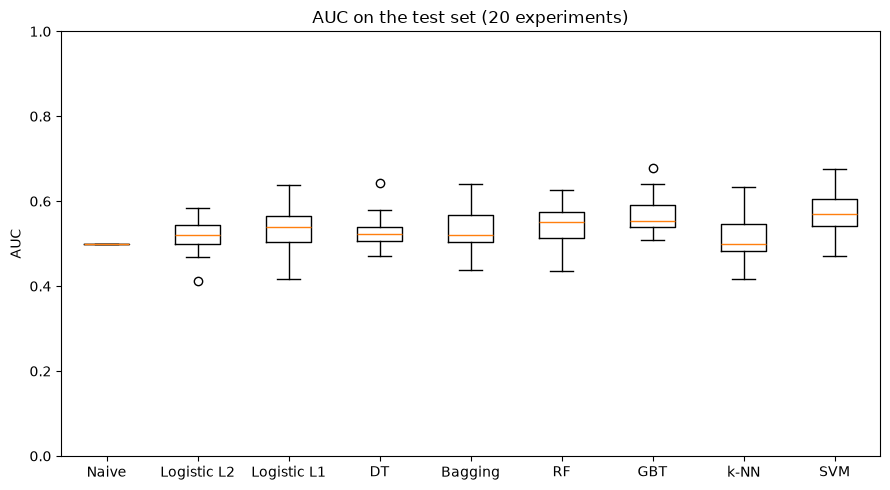

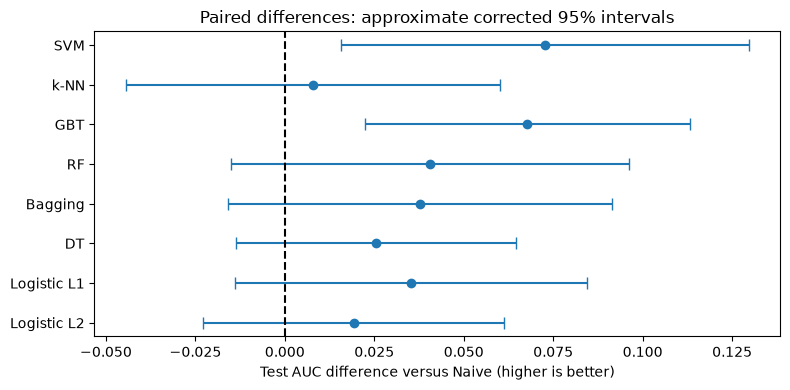

In [61]:
from scipy.stats import t as t_distribution
from warnings import warn

# One row per experiment, with each model evaluated on the same split
classification_scores = classification_results.pivot(index='experiment', columns='model', values='AUC')[classification_names]

# Boxplot shows test-set variation, with higher scores being better
plt.figure(figsize=(9, 5))
plt.boxplot([classification_scores[name].to_numpy() for name in classification_names])
plt.xticks(range(1, len(classification_names) + 1), classification_names)
plt.ylim(0, 1)
plt.ylabel('AUC')
plt.title(f'AUC on the test set ({len(classification_scores)} experiments)')
plt.tight_layout()
plt.show()

# Approximate corrected intervals for paired AUC differences versus Naive
differences = classification_scores.drop(columns='Naive').sub(classification_scores['Naive'], axis=0)
number_of_splits = len(differences)
classification_intervals = None
if number_of_splits < 2:
    warn('At least two experiments are needed for confidence intervals; interval plot skipped.')
else:
    sizes = classification_results.groupby('experiment')[['train size', 'test size']].first().loc[classification_scores.index]
    test_train_ratio = (sizes['test size'] / sizes['train size']).mean()
    standard_error = np.sqrt((1 / number_of_splits + test_train_ratio) * differences.var(ddof=1))
    margin = t_distribution.ppf(0.975, df=number_of_splits - 1) * standard_error
    classification_intervals = pd.DataFrame({'mean difference': differences.mean(), 'lower 95%': differences.mean() - margin,
                                             'upper 95%': differences.mean() + margin})

    plt.figure(figsize=(8, 4))
    plt.errorbar(classification_intervals['mean difference'], classification_intervals.index, xerr=margin, fmt='o', capsize=4)
    plt.axvline(0, color='black', linestyle='--')
    plt.xlabel('Test AUC difference versus Naive (higher is better)')
    plt.title('Paired differences: approximate corrected 95% intervals')
    plt.tight_layout()
    plt.show()


# Feature Selection (AI Slop)

This section uses Lasso and tree-based models to explore which predictors are useful for predicting `final_grade_pct`. Lasso can shrink coefficients to zero. For the tree models, we measure how much the holdout RMSE increases when each predictor is shuffled. These results are for exploration and are separate from the main model comparison.


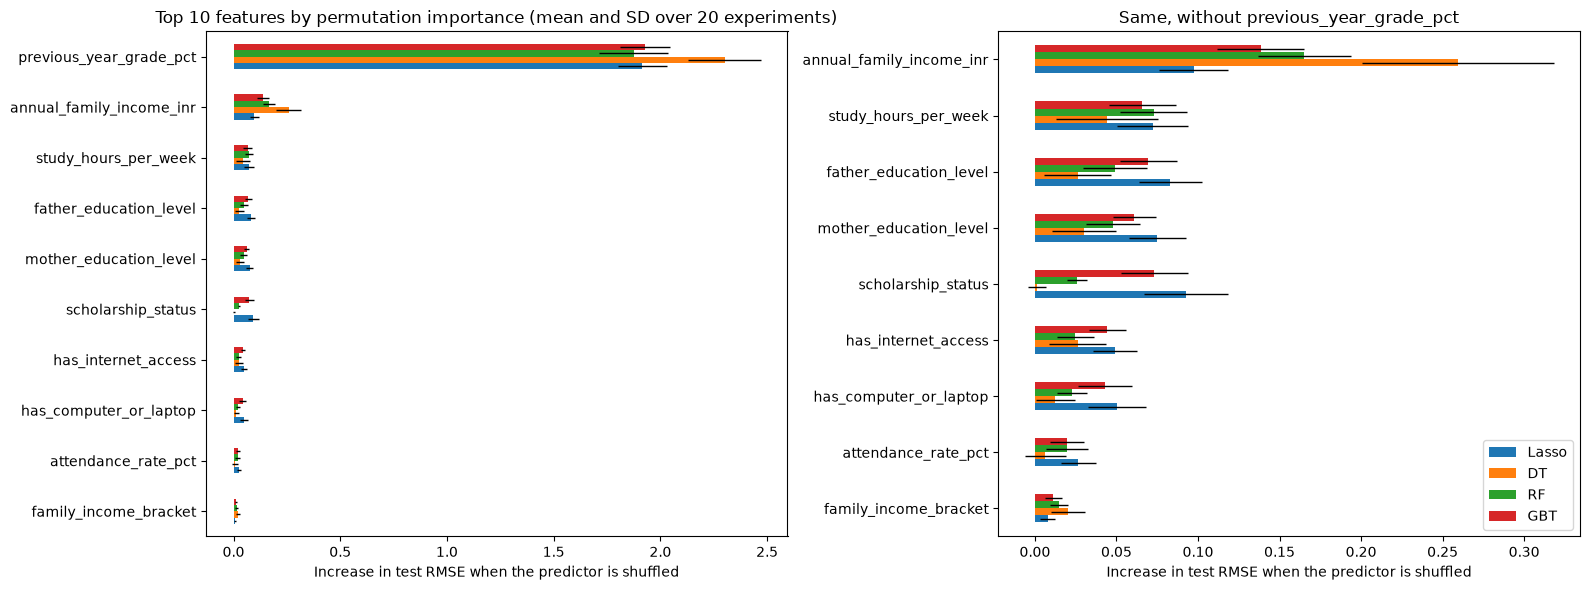

Share of the 20 experiments in which the Lasso kept each predictor:


,share of experiments
scholarship_status,1.00
attendance_rate_pct,1.00
previous_year_grade_pct,1.00
annual_family_income_inr,1.00
mother_education_level,1.00
family_size,1.00
single_parent_household,1.00
has_internet_access,1.00
has_computer_or_laptop,1.00
extra_tutoring,1.00


Lasso coefficients, 15 largest by size:


,mean coefficient,SD over experiments,share non-zero
num__previous_year_grade_pct,4.507,0.037,1.00
ordinal__scholarship_status,1.582,0.142,1.00
num__annual_family_income_inr,1.018,0.045,1.00
num__study_hours_per_week,0.827,0.049,1.00
num__has_computer_or_laptop,0.748,0.044,1.00
num__has_internet_access,0.724,0.046,1.00
ordinal__father_education_level,0.592,0.029,1.00
ordinal__mother_education_level,0.583,0.033,1.00
num__attendance_rate_pct,0.526,0.056,1.00
onehot__mother_occupation_Managerial / Executive,0.424,0.221,0.85


In [62]:
# Feature importance across the experiments
# The importances and the Lasso results were collected in the main script, so nothing is refitted here
from IPython.display import display

importance_by_experiment = pd.DataFrame(importance_records)       # one row per (experiment, model)
n_experiments = importance_by_experiment['experiment'].nunique()
model_order = ['Lasso', 'DT', 'RF', 'GBT']
grouped = importance_by_experiment.groupby('model')[PREDICTOR_COLS]
feature_importance_all = grouped.mean().T[model_order]            # mean importance over the experiments
feature_importance_sd = grouped.std().T[model_order]              # spread over the experiments

# Top 10 predictors by mean importance across the four models
top_features = feature_importance_all.mean(axis=1).nlargest(10).index
mean_plot = feature_importance_all.loc[top_features].sort_values('RF')
sd_plot = feature_importance_sd.loc[mean_plot.index]

# One predictor is far ahead of the rest, so the right panel drops it to show the other predictors
dominant_feature = mean_plot.mean(axis=1).idxmax()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
mean_plot.plot.barh(ax=axes[0], xerr=sd_plot, error_kw={'elinewidth': 1}, legend=False)
axes[0].set_title(f'Top 10 features by permutation importance (mean and SD over {n_experiments} experiments)')
mean_plot.drop(index=dominant_feature).plot.barh(ax=axes[1], xerr=sd_plot.drop(index=dominant_feature), error_kw={'elinewidth': 1})
axes[1].set_title(f'Same, without {dominant_feature}')
for ax in axes:
    ax.set_xlabel('Increase in test RMSE when the predictor is shuffled')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

# How often the Lasso kept each predictor (a predictor is kept if any of its encoded columns is non-zero)
selection_frequency = pd.DataFrame(lasso_selection_records).drop(columns='experiment').mean().sort_values(ascending=False)
print(f'Share of the {n_experiments} experiments in which the Lasso kept each predictor:')
display(selection_frequency.round(2).to_frame('share of experiments'))

# Lasso weights. Numeric columns are standardised, so their coefficient is the change in the predicted grade per 1 SD.
# Ordinal columns are per level step, and one-hot columns are relative to the first category.
coefficients = pd.DataFrame(lasso_coefficient_records).drop(columns='experiment')
coefficient_summary = pd.DataFrame({'mean coefficient': coefficients.mean(),
                                    'SD over experiments': coefficients.std(),
                                    'share non-zero': (coefficients != 0).mean()})
coefficient_summary = coefficient_summary.reindex(coefficient_summary['mean coefficient'].abs().sort_values(ascending=False).index)
print('Lasso coefficients, 15 largest by size:')
display(coefficient_summary.head(15).round(3))

# Stage 4: Unsupervised Learning - K-Means Clustering (Socioeconomic features)

Exploratory Data Analysis: Cluster students on socioeconomic features only, then check whether the groups differ in effort and grades.

### Step 1: Select features

In [63]:

km_df = GroupImputer().fit_transform(df)
km_df = km_df.drop(columns="family_income_bracket")

# ======= Ordinal encoding education ====== #
edu_rank = {
    "No Formal Education": 0,
    "Primary": 1,
    "Secondary": 2,
    "Higher Secondary": 3,
    "Bachelor's Degree": 4,
    "Master's Degree": 5,
    "Doctorate": 6
}

km_df['father_edu'] = km_df['father_education_level'].map(edu_rank)
km_df['mother_edu'] = km_df['mother_education_level'].map(edu_rank)

# 'Unknown' doesn't map to a number, fill with median
km_df['father_edu'] = km_df["father_edu"].fillna(km_df['father_edu'].median())
km_df['mother_edu'] = km_df["mother_edu"].fillna(km_df['mother_edu'].median())

# ======= Log income ====== #
km_df['log_income'] = np.log(km_df['annual_family_income_inr'])

# ======= Do household columns track SES? ===== #
household = ['single_parent_household', 'family_size', 'num_siblings']

print("Correlation of household columns with SES features:")
display(km_df[household + ['log_income', 'father_edu', 'mother_edu']].corr().loc[household, ['log_income', 'father_edu', 'mother_edu']].round(3))

# ======= SES columns ====== #
ses_cols = ['log_income', 'father_edu', 'mother_edu']

print("Description of SES columns we are going to cluster on:")
display(km_df[ses_cols].describe().round(2))

Correlation of household columns with SES features:


,log_income,father_edu,mother_edu
single_parent_household,-0.003,0.014,0.003
family_size,0.002,0.008,0.013
num_siblings,0.001,0.009,0.009


Description of SES columns we are going to cluster on:


,log_income,father_edu,mother_edu
count,12000.00,12000.00,12000.00
mean,12.83,2.67,2.70
std,0.99,1.52,1.52
min,11.00,0.00,0.00
25%,12.17,2.00,2.00
50%,12.77,3.00,3.00
75%,13.39,4.00,4.00
max,16.79,6.00,6.00


Why these features:
- SES is usually measured by income, education and occupation. We've included income and education directtly. 
- Parents' occupation was left out as it has no natural order, and being a 'Homemaker' (the most common for mothers) goes with the highest median income, so it can't be ranked sensibly
- `has_internet_access` and `has_computer_or_laptop` were left out of the clustering. They are 0/1 columns, and in a separate experiment we conducted, K-Means tended to split along those values since everyone with the same value sat at exactly the same point. They ended up driving the clusters. Leaving them out allows K-Means to find the SES boundary by itself.

- Other columns were checked and left out:
    - `family_income_bracket` is a banded version of income column

    - `scholarship_status` is a result of low SES, not a measure of it
    - `single_parent_household`, `family_size` and `num_siblings` have almost no correlation with income or education (r approx 0)
    - `distance_to_school_km` mostly reflects rural vs urban.
- `school_type`, `residence_type` and the grade columns are kept out on purpose, so they can be compared between clusters afterwards

### Step 2: Scale features and choose k

We use Inertia & Silhouette to determine which k to pick.

Inertia
- Measures how compact the clusters are
- Lower is better for compactness, but inertia generally increases as we add more clusters, even if the extra clusters aren't meaningful.
- To choose no. clusters, we plot inertia against K and look for an elbow point after which adding clusters brings diminishing returns

Silhouette
- The silhouette score tells use whether each point is closer to its own cluster or other clusters
- Near 1: Well within its cluster and separated from others
- Near 0: Near a boundary between cluters
- Below 0: Closer on average to another cluster than its own

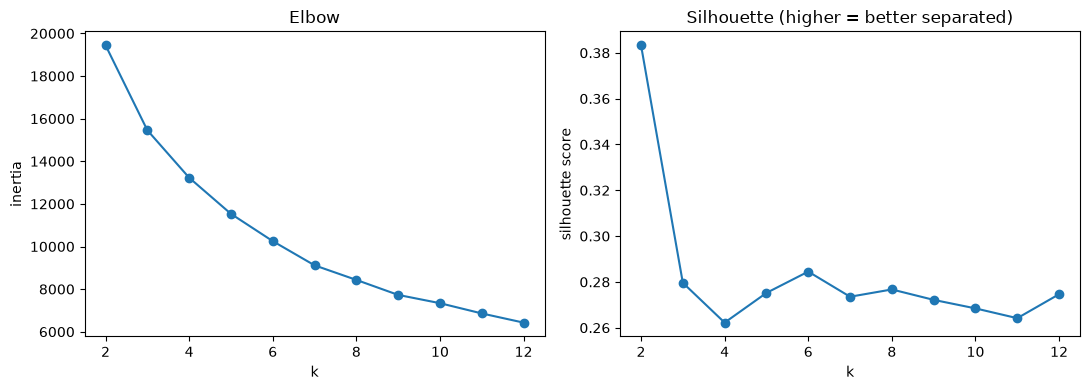

In [64]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

km_X = StandardScaler().fit_transform(km_df[ses_cols])

inertias = []
sil_scores = []

for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(km_X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(km_X, km.labels_, sample_size=3000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(range(2, 13), inertias, marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[0].set_title("Elbow")

axes[1].plot(range(2, 13), sil_scores, marker="o")
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette score")
axes[1].set_title("Silhouette (higher = better separated)")

plt.tight_layout()
plt.show() 

We pick k = 2
- Silhouette has one clear peak at k = 2 (0.37). It then drops to 0.27 at k = 3 and stays flat at 0.26 to 0.27 for every k up to 12, so no other number of clusters stands out.

- The elbow plot doesn't help: inertia drops smoothly with no clear bend, so the choice rests on the silhouette.

- With only 3 continuous features, there are no 0/1 columns to inflate the silhouette score, so the higher value really does mean better-separated groups.

- k = 2 is also the simplest result to interpret: a lower-SES and a higher-SES group.

### Step 3: Fit k = 2 and profile the clusters

Clusters are numbered so 0 = lower SES and 1 = higher SES.

Cluster counts breakdown:


cluster
0    6903
1    5097
Name: count, dtype: int64

Cluster means breakdown:


,log_income,father_edu,mother_edu
cluster,,,
0,12.28,1.78,1.79
1,13.57,3.89,3.94


Cluster income breakdown:


cluster
0    228061.0
1    692614.0
Name: annual_family_income_inr, dtype: float64

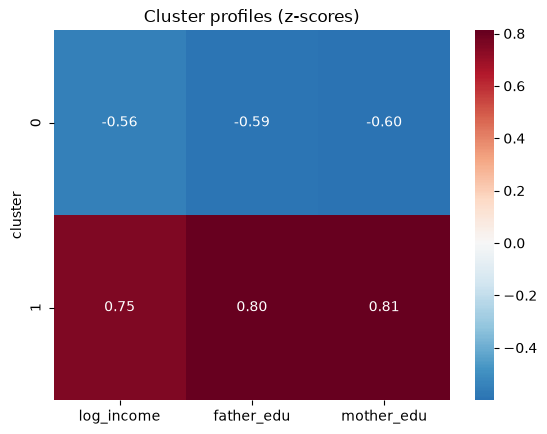

In [66]:
km = KMeans(n_clusters=2, n_init=10, random_state=42)
km_df["cluster"] = km.fit_predict(km_X)

# Renumber so 0 = lower income and 1 = higher
income_rank = km_df.groupby("cluster")["log_income"].mean().rank().astype(int) - 1
km_df["cluster"] = km_df["cluster"].map(income_rank)

print("Cluster counts breakdown:")
display(km_df["cluster"].value_counts().sort_index())

print("Cluster means breakdown:")
display(km_df.groupby('cluster')[ses_cols].mean().round(2))

print("Cluster income breakdown:")
display(km_df.groupby('cluster')['annual_family_income_inr'].median())

import seaborn as sns

# average z-score per cluster, 0 = overall average
km_X_df = pd.DataFrame(km_X, columns=ses_cols)
km_X_df["cluster"] = km_df["cluster"].values
profile = km_X_df.groupby("cluster").mean()

sns.heatmap(profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Cluster profiles (z-scores)")
plt.show()

### Step 4: Compare clusters on grades, digital access and background

### Grades

Average grades and effort by cluster:


,final_grade_pct,grade_change,study_hours_per_week,attendance_rate_pct,extra_tutoring,parental_involvement_score
cluster,,,,,,
0,63.68,4.61,13.78,84.81,0.19,3.15
1,71.37,4.63,15.30,87.25,0.29,3.38


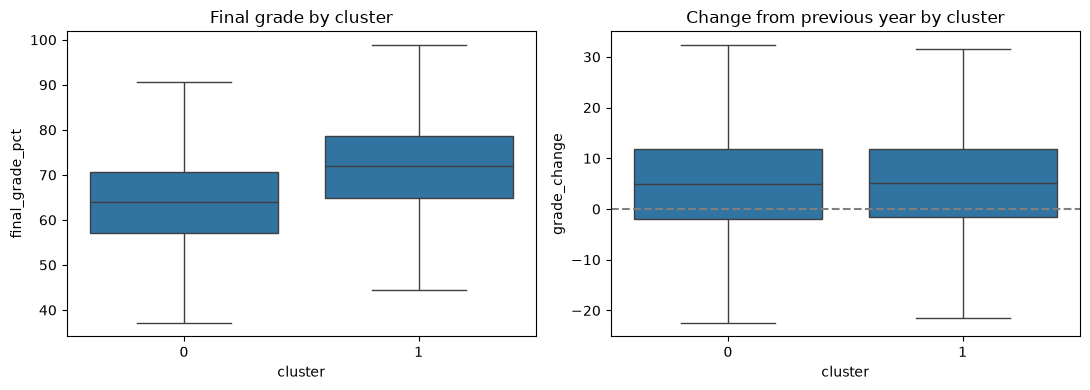

In [67]:
km_df["grade_change"] = km_df["final_grade_pct"] - km_df["previous_year_grade_pct"]

print("Average grades and effort by cluster:")
display(
    km_df.groupby("cluster")[
        [
            "final_grade_pct",
            "grade_change",
            "study_hours_per_week",
            "attendance_rate_pct",
            "extra_tutoring",
            "parental_involvement_score",
        ]
    ]
    .mean()
    .round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(
    data=km_df,
    x="cluster",
    y="final_grade_pct",
    showfliers=False,
    ax=axes[0],
)
axes[0].set_title("Final grade by cluster")

sns.boxplot(
    data=km_df,
    x="cluster",
    y="grade_change",
    showfliers=False,
    ax=axes[1],
)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set_title("Change from previous year by cluster")

plt.tight_layout()
plt.show()

### Digital Access

Internet and computer access weren't used for clustering, so we check how access differs between the SES groups and how it relates to grades within each group

In [68]:
# 0 = neither, 1 = internet or computer, 2 = both
km_df["devices"] = (
    km_df["has_internet_access"].astype(int)
    + km_df["has_computer_or_laptop"]
)

print("Share of each cluster with internet / a computer")
display(
    km_df.groupby("cluster")[
        ["has_internet_access", "has_computer_or_laptop"]
    ].mean().round(2)
)

print("Average final grade by cluster and number of devices")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["devices"],
        values=km_df["final_grade_pct"],
        aggfunc="mean",
    ).round(1)
)

print("Number of students by cluster and number of devices")
display(pd.crosstab(km_df["cluster"], km_df["devices"]))

Share of each cluster with internet / a computer


,has_internet_access,has_computer_or_laptop
cluster,,
0,0.44,0.34
1,0.58,0.51


Average final grade by cluster and number of devices


devices,0,1,2
cluster,,,
0,61.8,64.5,66.0
1,68.5,71.0,73.9


Number of students by cluster and number of devices


devices,0,1,2
cluster,,,
0,2657,3090,1156
1,1152,2323,1622


### Background

In [69]:
# Rows add up to 1
print("School type (share of each cluster)")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["school_type"],
        normalize="index",
    ).round(2)
)

print("Residence type (share of each cluster)")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["residence_type"],
        normalize="index",
    ).round(2)
)

print("Scholarship status (share of each cluster)")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["scholarship_status"],
        normalize="index",
    ).round(2)
)

School type (share of each cluster)


school_type,Government,Government-Aided,Private-Unaided
cluster,,,
0,0.45,0.2,0.35
1,0.45,0.2,0.35


Residence type (share of each cluster)


residence_type,Rural,Semi-Urban,Urban
cluster,,,
0,0.35,0.23,0.42
1,0.36,0.22,0.42


Scholarship status (share of each cluster)


scholarship_status,Full,No Scholarship,Partial
cluster,,,
0,0.10,0.69,0.20
1,0.04,0.89,0.07


### Findings so far

**Cluster structure**

- There is one natural split in income and parents’ education: **lower SES** (cluster 0, 57% of students, median income 230k, parents’ education around primary to secondary level) and **higher SES** (cluster 1, 43%, median income 690k, parents’ education around higher secondary to a bachelor’s degree).

- This is the clearest structure found (silhouette 0.37). It is still moderate, so the groups are more of a continuum rather than completely separate types.

**Grades**

- Higher-SES students average about 8 points higher (71.4 vs. 63.7), and their whole grade range is shifted up.

- Both groups improved on the previous year by about the same amount (+4.6), so the higher-SES group starts ahead rather than pulling further ahead.

- Effort differs only a little: 13.8 vs. 15.3 study hours per week, and 85% vs. 87% attendance. Tutoring is the clearest difference: 29% vs. 19%.

**Digital access**

- Higher-SES students are more likely to have devices: 58% have internet and 51% have a computer, compared with 44% and 34% in the lower-SES group.

- Within both groups, each extra device goes with about 2 to 3 more points:
  - Lower SES: 61.8 (neither) → 64.4 (one) → 66.0 (both)

  - Higher SES: 68.5 → 71.1 → 73.8
- At every level of access, higher-SES students are about 7 to 8 points ahead.
- SES and digital access look roughly **additive**: background is the bigger factor, and devices go with a similar extra gain in both groups.
- A lower-SES student with both devices (66.0) still averages below a higher-SES student with neither (68.5).

**Background**

- School type and residence are almost identical in both groups (about 45% government schools and about 35% rural), so neither separates the SES groups in this data.

- Scholarships go mostly to lower-SES students: 30% have one (full or partial), compared with 11% of the higher-SES group.

### Step 5: Visualize Clusters in 2D (PCA)

PCA reduces the 3 scaled features into 2 components so the clusters can be plotted. With only 2 clusters, a single scatter plot colored by cluster is readable

Share of variance explained by each component


PC1    0.679
PC2    0.164
dtype: float64

What each component is made of


,PC1,PC2
log_income,0.57,0.82
father_edu,0.58,-0.47
mother_edu,0.58,-0.34


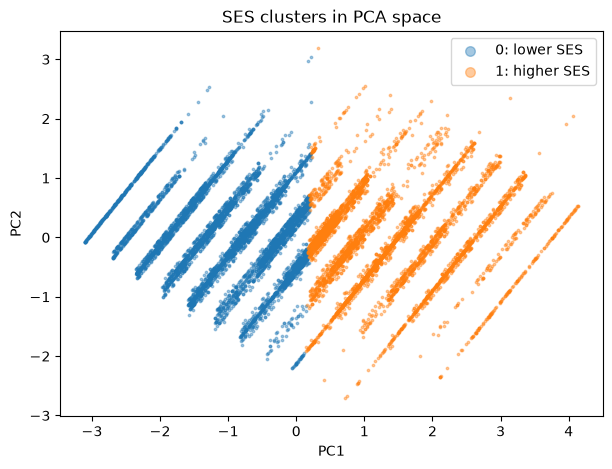

In [70]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pcs = pca.fit_transform(km_X)

print("Share of variance explained by each component")
display(
    pd.Series(
        pca.explained_variance_ratio_,
        index=["PC1", "PC2"],
    ).round(3)
)

print("What each component is made of")
display(
    pd.DataFrame(
        pca.components_.T,
        index=ses_cols,
        columns=["PC1", "PC2"],
    ).round(2)
)

lower = km_df["cluster"].values == 0

plt.figure(figsize=(7, 5))
plt.scatter(
    pcs[lower, 0], pcs[lower, 1],
    s=3, alpha=0.4, label="0: lower SES",
)
plt.scatter(
    pcs[~lower, 0], pcs[~lower, 1],
    s=3, alpha=0.4, label="1: higher SES",
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(markerscale=4)
plt.title("SES clusters in PCA space")
plt.show()

Findings for PCA
- Two components explain 84% of the variance. PC1 (67%) is overall SES: income and both parents’ education load about equally. PC2 (17%) mostly separates income from education, for example, families with high income but less-educated parents.

- The two clusters split cleanly along PC1: lower SES on the left, higher SES on the right. They meet in the middle without a gap, which fits the moderate silhouette: the split is a boundary drawn through a continuum.

- The points fall in diagonal stripes because parents’ education is a whole number from 0 to 6. Each stripe is one combination of father’s and mother’s education, and income spreads students along it.

###  Step 6: Check cluster stability
Would a different sample of students give the same split? If not, the boundary is partly luck.
- Shuffle the students and split them into two halves of 6,000.
- Fit one model on each half, then have both models label all 12,000 students so their results can be compared.
- Score the agreement with the adjusted Rand index (ARI): 1 = identical groupings, 0 = no better than random. Cluster numbers don’t matter, only which students end up together.
- Repeat 10 times.

In [71]:
from sklearn.metrics import adjusted_rand_score

# Fit on two random halves, then compare how each half's model labels everyone
half_scores = []

for seed in range(10):
    idx = np.random.default_rng(seed).permutation(len(km_X))
    half_a = km_X[idx[:6000]]
    half_b = km_X[idx[6000:]]

    km_a = KMeans(n_clusters=2, n_init=10, random_state=seed).fit(half_a)
    km_b = KMeans(n_clusters=2, n_init=10, random_state=seed + 100).fit(half_b)

    half_scores.append(
        adjusted_rand_score(km_a.predict(half_b), km_b.predict(half_b))
    )

print(np.round(half_scores, 3))
print("mean:", round(np.mean(half_scores), 3))

[0.973 0.958 0.994 0.956 0.911 0.972 0.99  0.987 0.982 0.951]
mean: 0.967


Findings: Step 6 (stability)
- The two halves found nearly the same split every time (ARI 0.91 to 1.0, mean 0.97), so the lower/higher SES boundary doesn’t depend on which students are in the sample.
- Stability doesn’t mean the groups are natural types. K-Means can cut a continuum in the same place every time, and the PCA plot shows no gap between the clusters. The split is a reliable boundary, not proof of two separate kinds of student.